# subset_final_snakemake — final clean pipeline

Single-cell NOMe-HiC of GM12878 + IMR90, snakemake outputs.

Decisions locked in after the exploration round (see `subset_final_snakemake_exploration.ipynb`):

| Modality | Embedding for clustering | Leiden res. | Notes |
|----------|--------------------------|-------------|-------|
| **HCG methylation** | SVD top-9 → **Harmony** | 0.6 | n_pc_graph=9, k=25 |
| **Hi-C** | hicluster SVD top-10 → **Harmony** | 0.5 | n_pc_graph=10, k=25 |
| **GCH accessibility** | all-bin SVD → **Harmony** (required — samples otherwise dominate) | 1.2 | n_pc_graph=20, k=50 → 9 clu (sweep best: sil_ct=0.109, ari_ct=0.611, knn_acc=0.857) |

Cell-type annotation: per HCG cluster pseudobulk, Pearson correlation against 250 kb bulk methylation references (`bulk_methylation_{GM12878,IMR90}.txt.gz`).

In [1]:
# §1 Setup
Sys.setenv(RETICULATE_PYTHON = "/projects/b1198/epifluidlab/yoshii/software/conda/envs/scnomehic/bin/python")
library(reticulate)
use_python(Sys.getenv("RETICULATE_PYTHON"), required = TRUE)

suppressPackageStartupMessages({
  library(umap); library(impute); library(igraph); library(cccd); library(Matrix)
  library(rhdf5); library(RColorBrewer); library(harmony)
  library(dplyr); library(tidyr); library(tibble); library(ggplot2); library(patchwork)
})
set.seed(42)

WORKDIR <- "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake"
OUT_DIR <- file.path(WORKDIR, "subset_clustering", "250kb_denovo")
OUT_TAB <- file.path(OUT_DIR, "tables")
OUT_FIG <- file.path(OUT_DIR, "figures")
ANN_DIR <- file.path(OUT_DIR, "annotation")
for (d in c(OUT_TAB, OUT_FIG, ANN_DIR)) dir.create(d, recursive = TRUE, showWarnings = FALSE)
setwd(WORKDIR); par(bg = "white")

In [2]:
# §2 Helpers
filter_high_na_genes <- function(mat, thr = 0.5) {
  mat[rowMeans(is.na(mat)) < thr, , drop = FALSE]
}

quantile_normalize <- function(mat) {
  nr <- nrow(mat); nc <- ncol(mat)
  max_non_na <- max(colSums(!is.na(mat)))
  sorted <- matrix(NA_real_, nrow = max_non_na, ncol = nc)
  for (i in seq_len(nc)) {
    v <- mat[, i]; v <- sort(v[!is.na(v)])
    sorted[seq_along(v), i] <- v
  }
  rmean <- rowMeans(sorted, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = nr, ncol = nc, dimnames = dimnames(mat))
  for (i in seq_len(nc)) {
    v <- mat[, i]; na_idx <- is.na(v)
    out[!na_idx, i] <- rmean[rank(v[!na_idx], ties.method = "average")]
  }
  out
}

impute_relaxed <- function(mat, k = 10) {
  suppressWarnings(suppressMessages(
    impute::impute.knn(mat, k = k, maxp = "p", rowmax = 0.95, colmax = 0.95)$data))
}

# Matches exploration §3 `perform_imputation` — uses impute.knn's
# stricter defaults (rowmax=0.5, colmax=0.8) so the SVD/Harmony/UMAP
# downstream agree with the §8c sweep figures.
perform_imputation <- function(data_mat, k = 10) {
  suppressWarnings(suppressMessages(
    impute::impute.knn(data_mat, k = k, maxp = "p")$data))
}

svd_embedding <- function(mat_features_x_cells, n_comps = 20) {
  data_t <- t(mat_features_x_cells)
  sv <- svd(scale(data_t))
  out <- sv$u[, seq_len(min(n_comps, ncol(sv$u))), drop = FALSE]
  rownames(out) <- rownames(data_t)
  attr(out, "svd") <- sv
  out
}

build_knn_graph <- function(emb, n_pc, k) {
  ng  <- min(n_pc, ncol(emb))
  knn <- cccd::nng(emb[, seq_len(ng), drop = FALSE], k = k)
  if ("weight" %in% igraph::edge_attr_names(knn))
    knn <- igraph::delete_edge_attr(knn, "weight")
  igraph::as.undirected(knn, mode = "collapse")
}

run_leiden <- function(emb, n_pc = 3, k = 25, resolution = 0.2) {
  g   <- build_knn_graph(emb, n_pc, k)
  com <- igraph::cluster_leiden(g, objective_function = "modularity",
                                resolution_parameter = resolution, n_iterations = 5)
  as.integer(igraph::membership(com))
}

partition_colors <- function(p, palette = brewer.pal(8, "Dark2")) {
  col <- rep(palette[1], length(p))
  for (i in unique(p)) col[p == i] <- palette[((i - 1) %% length(palette)) + 1]
  col
}

make_umap_df <- function(layout, meta) {
  as.data.frame(layout) %>% setNames(c("UMAP1", "UMAP2")) %>%
    tibble::rownames_to_column("cell") %>% dplyr::left_join(meta, by = "cell")
}

# --- figure savers: write BOTH pdf + png (and render inline) ---
# base graphics: `draw` is a no-arg function that renders the plot
save_fig_both <- function(basepath, width, height, draw) {
  pdf(paste0(basepath, ".pdf"), width = width, height = height); draw(); dev.off()
  png(paste0(basepath, ".png"), width = width, height = height, units = "in", res = 150); draw(); dev.off()
  invisible(NULL)
}
# ggplot objects
ggsave_both <- function(basepath, plot, width, height) {
  ggplot2::ggsave(paste0(basepath, ".pdf"), plot, width = width, height = height)
  ggplot2::ggsave(paste0(basepath, ".png"), plot, width = width, height = height, dpi = 150)
  invisible(NULL)
}


In [4]:
# §3 Metadata
qc     <- read.table(file.path(WORKDIR, "QC", "cortex_qc_summary.txt"),
                     header = TRUE, sep = "\t", stringsAsFactors = FALSE, comment.char = "")
passed <- readLines(file.path(WORKDIR, "QC", "cortex_passed.txt"))
submetadata <- qc[qc$prefix %in% passed, , drop = FALSE]
rownames(submetadata) <- submetadata$prefix
submetadata$name   <- submetadata$prefix
submetadata$cell   <- submetadata$prefix
submetadata$sample <- sub("_.*", "", submetadata$prefix)
cat("Cells (QC-passed):", nrow(submetadata), "  batches:\n"); print(table(submetadata$sample))

# --- plate_ID + library_prep_date, merged from the two library sample sheets ---
# cortex_qc_summary.txt carries no plate/date, and the old ../metadata.txt covers
# only 1143 cells. These spreadsheets cover essentially every cell (1576/1577):
#   rep1 (scNH)   key = scNH_c57cortex_L{Lane}_{cell_number}.{barcode, col `...12`}
#   rep2 (batch2) key = batch2_sc{N}.{cell_index_sequence}, N from Novogene_ID mc_rep2_{N}
suppressPackageStartupMessages(library(readxl))
xl1 <- file.path(WORKDIR, "scNH_micecortex_rep1_demultiplex_w_plateID_libprep_info (1).xlsx")
xl2 <- file.path(WORKDIR, "samplesheet_sc_micecortex_rep2_05082024_with_plateID_libprep_info (1).xlsx")
r1  <- readxl::read_excel(xl1, sheet = 1)
r2  <- rbind(readxl::read_excel(xl2, "Pool1")[, c("Novogene_ID", "cell_index_sequence", "plate_ID", "Library_prep_date")],
             readxl::read_excel(xl2, "Pool2")[, c("Novogene_ID", "cell_index_sequence", "plate_ID", "Library_prep_date")])
lib_key   <- c(paste0("scNH_c57cortex_L", r1$Lane, "_", r1$cell_number, ".", r1[["...12"]]),
               paste0("batch2_sc", sub("mc_rep2_", "", r2$Novogene_ID), ".", r2$cell_index_sequence))
lib_plate <- c(as.character(r1$plate_ID), as.character(r2$plate_ID))
lib_dt    <- c(as.character(as.Date(r1$library_prep_date)), as.character(as.Date(r2$Library_prep_date)))
keep      <- !duplicated(lib_key)
lib_plate <- setNames(lib_plate[keep], lib_key[keep])
lib_dt    <- setNames(lib_dt[keep],    lib_key[keep])

submetadata$plate_ID          <- unname(lib_plate[rownames(submetadata)])
submetadata$library_prep_date <- unname(lib_dt[rownames(submetadata)])
# A few cells have no exact (lane, cell_number, barcode) row in the sheets. Within a
# group (= cell name minus its barcode) the 8 barcodes split into two FIXED 4-barcode
# sets, each belonging to one plate / prep-date:
#   set A = ACTTGA/CAGATC/CTTGTA/TAGCTT     set B = ATCACG/CGATGT/GCCAAT/TGACCA
# (verified: 209/218 group-plate blocks are exactly one of those two sets; the rest are
# strict subsets of them). So a cell with no row inherits the plate/date of the other
# cells in its group that share its barcode set -- plate/date is NOT constant across a
# whole group, so this must be done per barcode set, not per group.
BC_A <- c("ACTTGA", "CAGATC", "CTTGTA", "TAGCTT")
BC_B <- c("ATCACG", "CGATGT", "GCCAAT", "TGACCA")
bc_set  <- function(b) ifelse(b %in% BC_A, "A", ifelse(b %in% BC_B, "B", NA_character_))
grp_key <- function(x) paste0(sub("\\.[^.]*$", "", x), "|", bc_set(sub(".*\\.", "", x)))
mode1   <- function(x) names(sort(table(x), decreasing = TRUE))[1]

lib_g      <- grp_key(names(lib_plate))
plate_by_g <- tapply(unname(lib_plate), lib_g, mode1)
date_by_g  <- tapply(unname(lib_dt),    lib_g, mode1)
miss <- is.na(submetadata$library_prep_date)
if (any(miss)) {
  g <- grp_key(rownames(submetadata)[miss])
  submetadata$plate_ID[miss]          <- unname(plate_by_g[g])
  submetadata$library_prep_date[miss] <- unname(date_by_g[g])
  cat("inferred plate/date for", sum(miss), "cell(s) from group + barcode set:",
      paste(rownames(submetadata)[miss], collapse = ", "), "\n")
}
cat("plate/date for", sum(!is.na(submetadata$library_prep_date)), "/", nrow(submetadata),
    "cells |  plates:", length(unique(na.omit(submetadata$plate_ID))),
    " dates:", length(unique(na.omit(submetadata$library_prep_date))), "\n")


Cells (QC-passed): 1577   batches:

batch2   scNH 
   875    702 


New names:
• `` -> `...12`


inferred plate/date for 1 cell(s) from group + barcode set: scNH_c57cortex_L2_c14.CTTGTA 
plate/date for 1577 / 1577 cells |  plates: 10  dates: 20 


## §4 HCG methylation — Harmony SVD clustering

In [ ]:
# §4a HCG: load + impute + SVD
hcg_path <- file.path(WORKDIR, "QC", "methylation_matrices", "methylation_matrix_HCG_250kb.tsv.gz")
hcg_mat <- read.table(gzfile(hcg_path), header = TRUE, sep = "\t",
                      row.names = 1, check.names = FALSE,
                      na.strings = c("NA", "", "NaN"))
hcg_mat <- data.matrix(hcg_mat)
common  <- intersect(rownames(hcg_mat), submetadata$name)
hcg_mat <- hcg_mat[common, , drop = FALSE]
hcg_mat <- hcg_mat[, colSums(is.na(hcg_mat)) < 0.8 * nrow(hcg_mat), drop = FALSE]
cat("HCG (cells x bins) after filter:", dim(hcg_mat), "\n")

# impute.knn draws on the RNG, so the seed is what makes the SVD -- and
# therefore Harmony, the Leiden partition and the labels -- reproducible.
set.seed(42)
hcg_imputed <- impute_relaxed(hcg_mat, k = 10)
rownames(hcg_imputed) <- rownames(hcg_mat); colnames(hcg_imputed) <- colnames(hcg_mat)

HCG.svd_full <- svd(scale(hcg_imputed))
HCG.svd      <- HCG.svd_full$u
rownames(HCG.svd) <- rownames(hcg_imputed)
cat("HCG SVD:", dim(HCG.svd), "\n")

# save pre-Harmony SVD (top-9) for the §8.7c before-correction joint UMAP
write.table(HCG.svd[, seq_len(9)], file.path(OUT_TAB, "hcg_svd_raw.txt"), sep = "\t", quote = FALSE)


In [15]:
# §4b HCG: Harmony on top-9 SVD, then UMAP + Leiden
# Calibrated in exploration: n_pc=9, k=25, resolution=0.6
# Harmony removes the per-sample (batch2 vs scNH) shift before clustering;
# n_pc=9 is the locked dim from the exploration sweep.
meta_h <- submetadata[rownames(HCG.svd), , drop = FALSE]
set.seed(42)
HCG.harmony <- suppressMessages(suppressWarnings(
  RunHarmony(HCG.svd[, 1:9], meta_h, vars_use = "sample", verbose = FALSE)))
rownames(HCG.harmony) <- rownames(HCG.svd)

set.seed(42)
HCG.umap <- umap(as.matrix(HCG.harmony))
HCG.part <- run_leiden(HCG.harmony, n_pc = 9, k = 25, resolution = 1)
names(HCG.part) <- rownames(HCG.harmony)
submetadata$hcg_cluster <- NA_integer_
submetadata[rownames(HCG.harmony), "hcg_cluster"] <- HCG.part
cat("HCG Leiden:\n"); print(table(HCG.part))

write.table(HCG.harmony,     file.path(OUT_TAB, "hcg_embedding_harmony.txt"), sep = "\t", quote = FALSE)
write.table(HCG.umap$layout, file.path(OUT_TAB, "hcg_umap.txt"),              sep = "\t", quote = FALSE)


HCG Leiden:
HCG.part
  1   2   3   4   5   6   7   8   9  10 
228 135 176 194 203  99  55 243  69 175 


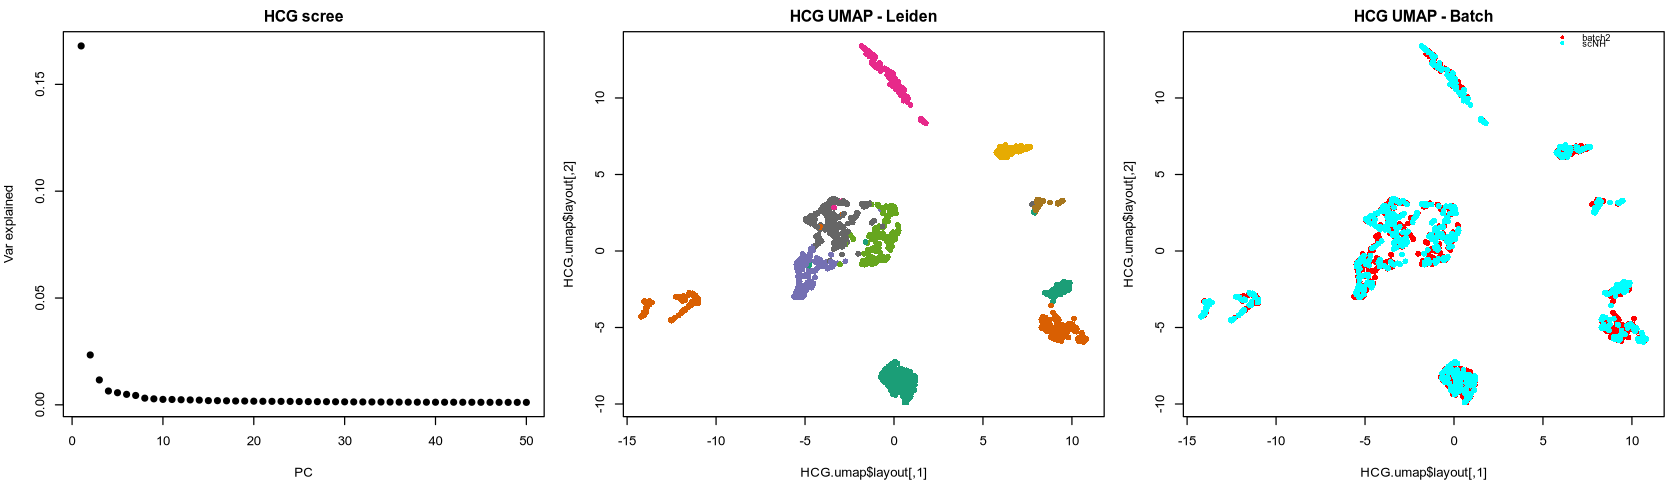

In [16]:
options(repr.plot.width = 14, repr.plot.height = 4)
# §4c HCG visualization
bfact <- as.factor(submetadata[rownames(HCG.umap$layout), "sample"])
draw_hcg <- function() {
  par(mfrow = c(1, 3), mar = c(4, 4, 2, 1), bg = "white")
  d <- HCG.svd_full$d
  plot(d[1:50]^2 / sum(d^2), pch = 19, xlab = "PC", ylab = "Var explained", main = "HCG scree")
  plot(HCG.umap$layout, col = partition_colors(HCG.part), pch = 16, main = "HCG UMAP - Leiden")
  plot(HCG.umap$layout, col = rainbow(length(levels(bfact)))[bfact], pch = 16, main = "HCG UMAP - Batch")
  legend("topright", legend = levels(bfact), col = rainbow(length(levels(bfact))), pch = 16, cex = 0.7, bty = "n")
}
save_fig_both(file.path(OUT_FIG, "hcg"), 14, 4, draw_hcg)   # hcg.pdf + hcg.png
draw_hcg()

## §5 Hi-C — Harmony hicluster SVD clustering

In [8]:
# §5a HiC: load + Harmony on top-10 PCs, then UMAP + Leiden
# Calibrated in exploration: n_pc=10, k=25, resolution=0.5 (HIC_RES)
# Harmony removes the per-sample shift in the hicluster SVD before clustering.
hic_h5  <- file.path(WORKDIR, "06.hiccluster_snakemake",
                     "hicluster_250kb_embed_dir",
                     "all_merged.pad1_std1_rp0.5_sqrtvc.svd20.hdf5")
hic_ord <- file.path(WORKDIR, "06.hiccluster_snakemake",
                     "hicluster_250kb_chr1_impute_file_list.txt")
hic_mat <- t(h5read(hic_h5, "/data"))
ind     <- readLines(hic_ord)
ind     <- sub("_chr\\S+", "", sub("\\S+chr1/", "", ind, perl = TRUE), perl = TRUE)
stopifnot(length(ind) == nrow(hic_mat))
rownames(hic_mat) <- ind
common  <- intersect(rownames(hic_mat), submetadata$name)
hic_mat <- hic_mat[common, , drop = FALSE]
cat("HiC SVD (cells x PCs):", dim(hic_mat), "\n")

meta_h <- submetadata[rownames(hic_mat), , drop = FALSE]
set.seed(42)
hic_harmony <- suppressMessages(suppressWarnings(
  RunHarmony(hic_mat[, 1:10], meta_h, vars_use = "sample", verbose = FALSE)))
rownames(hic_harmony) <- rownames(hic_mat)

set.seed(42)
hic_umap <- umap(as.matrix(hic_harmony))
hic_part <- run_leiden(hic_harmony, n_pc = 10, k = 25, resolution = 0.5)
names(hic_part) <- rownames(hic_harmony)
submetadata$hic_cluster <- NA_integer_
submetadata[rownames(hic_harmony), "hic_cluster"] <- hic_part
cat("HiC Leiden:\n"); print(table(hic_part))

write.table(hic_harmony,     file.path(OUT_TAB, "hic_embedding_harmony.txt"), sep = "\t", quote = FALSE)
write.table(hic_umap$layout, file.path(OUT_TAB, "hic_umap.txt"),              sep = "\t", quote = FALSE)

# save pre-Harmony Hi-C SVD (top-10) for the §8.7c before-correction joint UMAP
write.table(hic_mat[, seq_len(10)], file.path(OUT_TAB, "hic_svd_raw.txt"), sep = "\t", quote = FALSE)


HiC SVD (cells x PCs): 1577 20 
HiC Leiden:
hic_part
  1   2   3   4 
930 360 255  32 


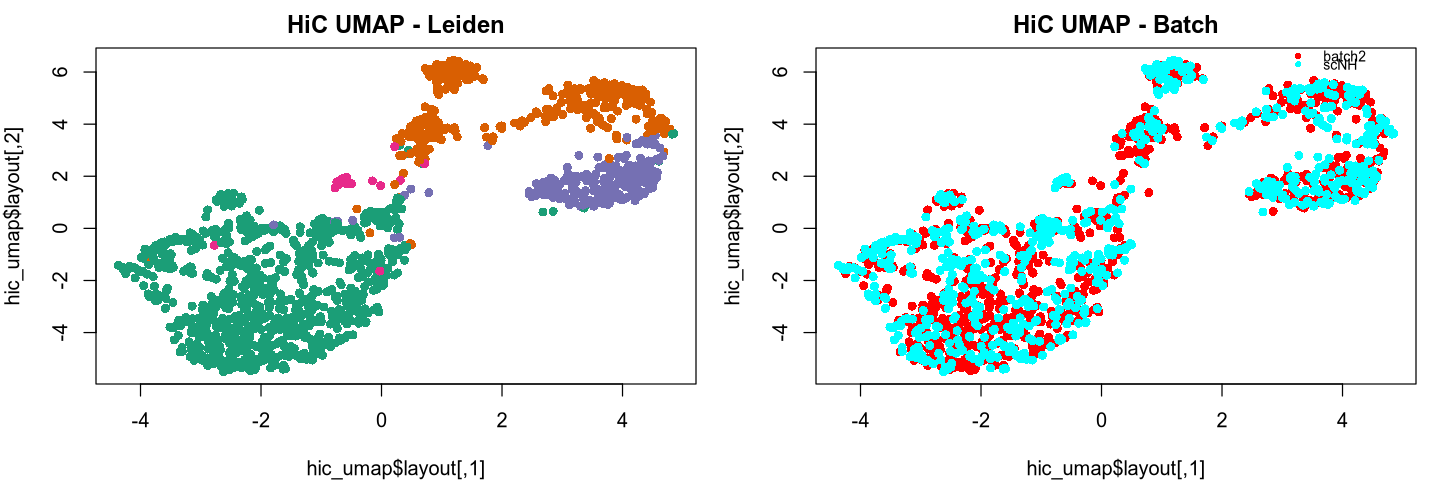

In [9]:
options(repr.plot.width = 12, repr.plot.height = 4)
# §5b HiC visualization
bfact <- as.factor(submetadata[rownames(hic_umap$layout), "sample"])
draw_hic <- function() {
  par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
  plot(hic_umap$layout, col = partition_colors(hic_part), pch = 16, main = "HiC UMAP - Leiden")
  plot(hic_umap$layout, col = rainbow(length(levels(bfact)))[bfact], pch = 16, main = "HiC UMAP - Batch")
  legend("topright", legend = levels(bfact), col = rainbow(length(levels(bfact))), pch = 16, cex = 0.7, bty = "n")
}
save_fig_both(file.path(OUT_FIG, "hic"), 12, 4, draw_hic)   # hic.pdf + hic.png
draw_hic()

## §6 GCH accessibility — all bins → SVD → Harmony → Leiden

Harmony is required: without batch correction the two samples (`batch2`,
`scNH`) dominate PC1 and dwarf cell-type structure. HVG selection is **not**
applied — exploration showed the HVG-restricted embedding failed to separate
neuron subtypes; the all-bin Harmony embedding is what §8c sweeps.

In [10]:
# §6a GCH: load + quantile normalize
gch_path <- file.path(WORKDIR, "QC", "methylation_matrices", "methylation_matrix_GCH_250kb.tsv.gz")
gch_mat <- read.table(gzfile(gch_path), header = TRUE, sep = "\t",
                      row.names = 1, check.names = FALSE,
                      na.strings = c("NA", "", "NaN"))
gch_mat <- data.matrix(gch_mat)
common  <- intersect(rownames(gch_mat), submetadata$name)
gch_mat <- gch_mat[common, , drop = FALSE]
gene_acc <- filter_high_na_genes(t(gch_mat), 0.5)   # bins x cells
cat("GCH after NA filter (bins x cells):", dim(gene_acc), "\n")

normalized_data <- quantile_normalize(as.matrix(gene_acc))

GCH after NA filter (bins x cells): 10368 1577 


In [ ]:
# §6b GCH: ALL bins -> impute -> SVD (no HVG selection)
# Decision (from exploration): HVG-restricted embedding did not separate
# neuron subtypes well; use all bins and rely on Harmony in §6c to handle
# the sample (batch) shift that otherwise dominates the raw SVD.
sub_norm <- normalized_data

drop_cells <- colMeans(is.na(sub_norm)) > 0.8
if (any(drop_cells)) sub_norm <- sub_norm[, !drop_cells, drop = FALSE]
bin_na <- rowMeans(is.na(sub_norm))
if (any(bin_na > 0.8)) sub_norm <- sub_norm[bin_na <= 0.8, , drop = FALSE]
cat("GCH all-bins (bins x cells):", dim(sub_norm), "\n")

# impute.knn draws on the RNG, so the seed is what makes the SVD -- and
# therefore Harmony, the Leiden partition and the labels -- reproducible.
set.seed(42)
imp <- perform_imputation(sub_norm, k = 10)  # match exploration sweep (impute.knn defaults)
rownames(imp) <- rownames(sub_norm); colnames(imp) <- colnames(sub_norm)
gch_svd <- svd_embedding(imp, n_comps = 20)
cat("GCH SVD:", dim(gch_svd), "\n")

# save pre-Harmony GCH SVD (top-20) for the §8.7c before-correction joint UMAP
write.table(gch_svd[, seq_len(20)], file.path(OUT_TAB, "gch_svd_raw.txt"), sep = "\t", quote = FALSE)


In [12]:
# §6c GCH: Harmony + UMAP + Leiden
# Calibrated from exploration §8c (all-bins, Harmony-only sweep):
#   n_pc=20, k=50, res=1.20 -> 9 clusters
#   sil_ct=0.109, ari_ct=0.611, knn_acc=0.857
meta_h <- submetadata[rownames(gch_svd), , drop = FALSE]
set.seed(42)
gch_harmony <- suppressMessages(suppressWarnings(
  RunHarmony(gch_svd, meta_h, vars_use = "sample", verbose = FALSE)))

set.seed(42)
gch_umap <- umap(as.matrix(gch_harmony[, 1:20]))  # seed reset to match the exploration notebook
gch_part <- run_leiden(gch_harmony, n_pc = 20, k = 50, resolution = 1.20)
names(gch_part) <- rownames(gch_harmony)
submetadata$gch_cluster <- NA_integer_
submetadata[rownames(gch_harmony), "gch_cluster"] <- gch_part
cat("GCH Leiden:\n"); print(table(gch_part))

write.table(gch_harmony,     file.path(OUT_TAB, "gch_embedding_harmony.txt"), sep = "\t", quote = FALSE)
write.table(gch_umap$layout, file.path(OUT_TAB, "gch_umap.txt"),              sep = "\t", quote = FALSE)

GCH Leiden:
gch_part
  1   2   3   4   5   6   7   8   9 
351 198  59 210 107 189 227 104 132 


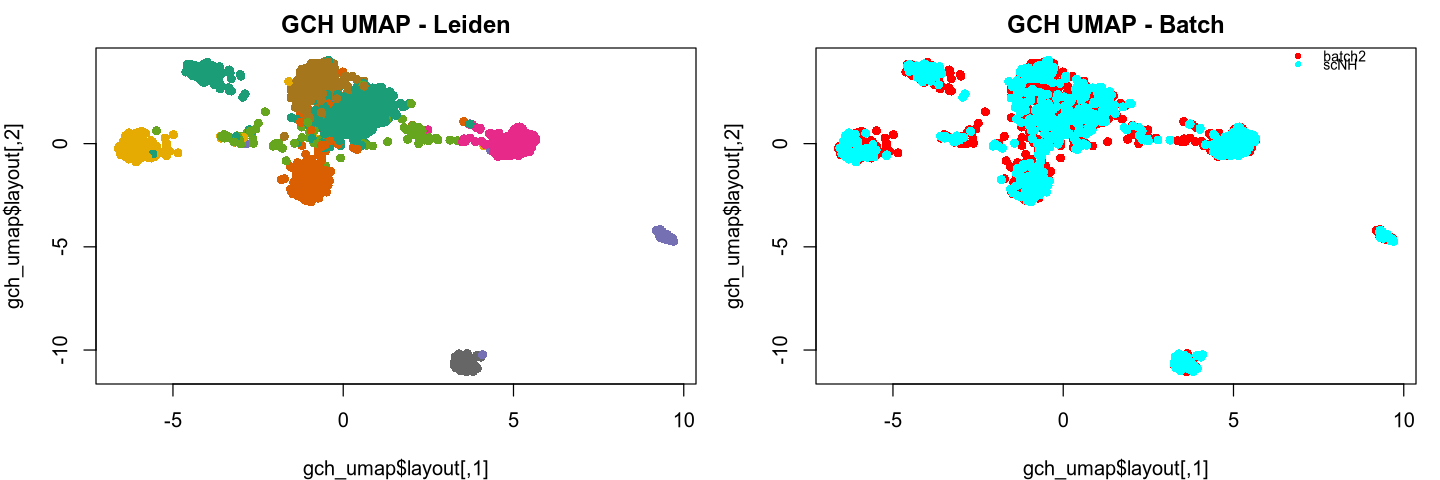

In [13]:
options(repr.plot.width = 12, repr.plot.height = 4)
# §6d GCH visualization
bfact <- as.factor(submetadata[rownames(gch_umap$layout), "sample"])
draw_gch <- function() {
  par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
  plot(gch_umap$layout, col = partition_colors(gch_part), pch = 16, main = "GCH UMAP - Leiden")
  plot(gch_umap$layout, col = rainbow(length(levels(bfact)))[bfact], pch = 16, main = "GCH UMAP - Batch")
  legend("topright", legend = levels(bfact), col = rainbow(length(levels(bfact))), pch = 16, cex = 0.7, bty = "n")
}
save_fig_both(file.path(OUT_FIG, "gch"), 12, 4, draw_gch)   # gch.pdf + gch.png
draw_gch()

## §7 Combined per-modality UMAP comparison

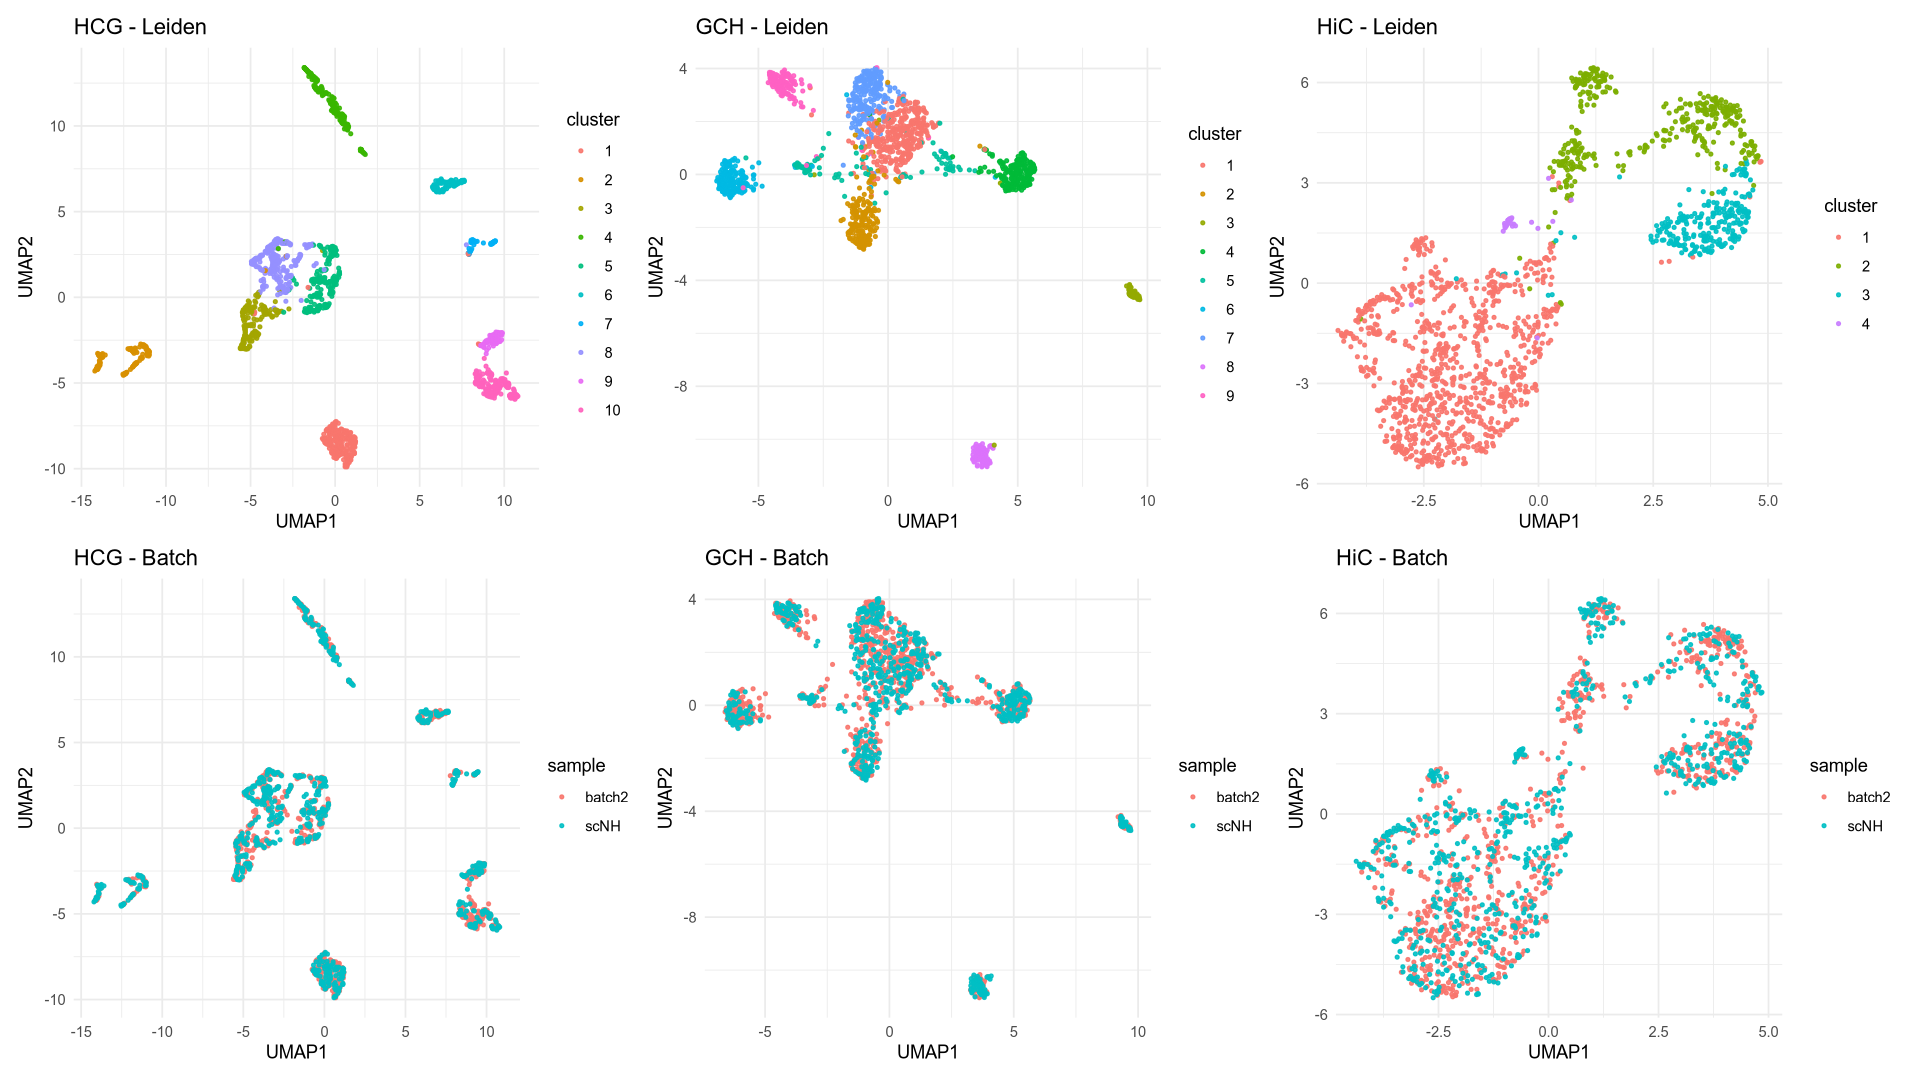

In [17]:
options(repr.plot.width = 16, repr.plot.height = 9)
smeta <- submetadata[, c("cell", "sample")]
df_hcg <- make_umap_df(HCG.umap$layout, smeta) %>% mutate(cluster = factor(HCG.part))
df_hic <- make_umap_df(hic_umap$layout,  smeta) %>% mutate(cluster = factor(hic_part))
df_gch <- make_umap_df(gch_umap$layout,  smeta) %>% mutate(cluster = factor(gch_part))

theme_u <- theme_minimal(base_size = 11) + theme(legend.position = "right")
mk <- function(df, col, title) ggplot(df, aes(UMAP1, UMAP2, colour = .data[[col]])) +
  geom_point(size = 0.8, alpha = 0.9) + ggtitle(title) + theme_u

comp <- (mk(df_hcg, "cluster", "HCG - Leiden") | mk(df_gch, "cluster", "GCH - Leiden") | mk(df_hic, "cluster", "HiC - Leiden")) /
        (mk(df_hcg, "sample",  "HCG - Batch")  | mk(df_gch, "sample",  "GCH - Batch")  | mk(df_hic, "sample",  "HiC - Batch"))
ggsave_both(file.path(OUT_FIG, "combined_umaps"), comp, 16, 9)
comp

## §8 Cell-type annotation — plain Leiden + atlas assignment

Neither the clustering parameters nor the cell types are chosen here.

1. **§8a Clustering.** One Leiden partition of the HCG Harmony embedding —
   `n_neighbors = 20`, `resolution = 0.3`, `random_state = 0`. No consensus over
   repeats, no `min_cluster_size` filter, no supervised merging. Every cell is
   assigned; there are no outliers. → 10 clusters.
2. **§8b Atlas assignment.** Each cluster is matched to the CEMBA isocortex
   major type with which its genome-wide gene-body mCG profile correlates most
   strongly (Spearman, top 3,000 variable genes, per-gene centred within each
   dataset). No marker genes are selected and no threshold is applied, so the
   **number of cell types is an outcome, not an input.** → 10 cell types.
3. **§8c Final labels.** The clusters are relabelled by their arg-max atlas type
   and the correlation is shown as a heatmap. There is no outlier-rescue step:
   plain Leiden leaves nothing to rescue.

**Cell types (10):** IT-L2/3, IT-L4, IT-L5/6, CT-L6 (Exc); Inhib (Inh);
ODC, OPC, ASC, MGC, PC/EC.

### Why plain Leiden and not consensus clustering

Consensus clustering (200 Leiden runs reconciled at `consensus_rate = 0.7`)
deliberately over-clusters, and on this dataset that surfaced a 21-cell NP-L6
group — too small to carry through the Hi-C analyses. A 48-configuration sweep
(`resolution_exploration.ipynb`) established that **no** consensus setting
removes NP-L6 while keeping the inhibitory subtypes and ODC/OPC apart, and that
raising `min_cluster_size` retires NP-L6 into IT-L5/6, which the atlas
contradicts. Plain Leiden at k = 20, resolution 0.3 dissolves it naturally, 20
of its 21 cells joining CT-L6, with no hand-merge.

**The cost, stated plainly:** Pvalb and Vip merge into one inhibitory group, and
47 cells previously called IT-L2/3 move into IT-L5/6.

### Three naming decisions

- **IT-L5/6** — IT-L5 and IT-L6 are not separable here. The margin between them
  is 0.007, it flips with the gene set or the similarity metric, and no gene-body
  marker distinguishes the cluster in either mCG or GCH. The name spans both
  rather than claiming one. Bootstrapping over genes puts IT-L5 or IT-L6 first in
  100% of resamples and IT-L4 in 0%, so the *label* is secure even though the
  layer is not.
- **Inhib** — this cluster is 48 Pvalb + 85 Vip by the earlier annotation, i.e.
  Vip is the majority. It must **not** be called Pvalb; the MGE-Pvalb arg-max
  only reflects that a merged inhibitory profile sits closest to that reference.
- **PC/EC** — one cluster holding both pericytes and endothelial cells, so the
  joint vascular label is kept.

**Free parameters that remain**, to be stated in the Methods rather than implied
away: `n_neighbors = 20` and `resolution = 0.3` (chosen to dissolve NP-L6 while
retaining the other distinctions — see the sweep); the embedding beneath
everything (250 kb bins, ≥20% coverage filter, `impute.knn` k=10, the leading
9 SVD components, Harmony on replicate); and the correlation filters (≥100 reads
per cluster-gene, 3,000 variable genes, isocortex atlas candidates with ≥40
cells). Assignments are unchanged over 500–18,295 genes, random gene subsets,
and Spearman / Pearson / Kendall / Jaccard.

In [18]:
# §8a Clustering — plain single-seed Leiden on the HCG Harmony embedding.
# k = 20 neighbours, resolution 0.8, seed 42. NO consensus over repeats, NO
# min_cluster_size filter, NO supervised merging. Every cell is assigned.
#
# Uses the notebook's own run_leiden() (§2), the same helper §4b/§5a/§6c use for
# the per-modality clusterings, so the whole pipeline is one self-contained R
# record with no external script and no python dependency.
#
# Why plain Leiden and not ALLCools ConsensusClustering: consensus deliberately
# over-clusters, which on this dataset surfaced a 21-cell NP-L6 group too small
# to carry through the Hi-C analyses. A 48-configuration sweep (see
# resolution_exploration.ipynb) showed no consensus setting removes NP-L6 while
# keeping the inhibitory subtypes and ODC/OPC apart, and that raising
# min_cluster_size retires it into IT-L5/6, which the atlas contradicts. Plain
# Leiden dissolves it naturally, its cells joining CT-L6, with no hand-merge.
# Cost, stated plainly: Pvalb and Vip merge into one inhibitory group, and ~47
# cells previously called IT-L2/3 move into IT-L5/6.
#
# On resolution 0.8: run_leiden() builds an UNWEIGHTED kNN graph (cccd::nng),
# whereas the sweep in resolution_exploration.ipynb used scanpy's weighted UMAP
# connectivities. The two need different resolutions for the same granularity --
# 0.8 here corresponds to 0.3 there, and the partitions agree at ARI 0.965 /
# 98.5% of cells. Resolution is therefore not comparable between the two
# notebooks; cluster COUNT is.
#
# SEED: 42, fixed. Not cosmetic -- seeds 1/42/100/2024 give 10 clusters
# (ARI 0.965 against the reference partition) but seed 7 gives 11. State the
# seed in the Methods, as §4b/§5a/§6c already do.
K_NEIGHBORS <- 20      # n_neighbors for the kNN graph
LEIDEN_RES  <- 0.8     # Leiden resolution (unweighted graph; see note above)
SEED        <- 42      # fixed; the partition is seed-sensitive

set.seed(SEED)
leiden_part <- run_leiden(HCG.harmony, n_pc = 9, k = K_NEIGHBORS,
                          resolution = LEIDEN_RES)
names(leiden_part) <- rownames(HCG.harmony)

submetadata$leiden_cluster <- NA_character_
submetadata[rownames(HCG.harmony), "leiden_cluster"] <- as.character(leiden_part)
stopifnot(!any(is.na(submetadata$leiden_cluster)))   # plain Leiden assigns every cell
N_CLUSTERS <- length(unique(submetadata$leiden_cluster))
cat(sprintf("k = %d, resolution = %s, seed = %d -> %d clusters, no outliers\n",
            K_NEIGHBORS, LEIDEN_RES, SEED, N_CLUSTERS))
print(table(cluster = submetadata$leiden_cluster))

# Fail loudly rather than let a different partition propagate silently into the
# annotation. The 10-cluster plateau runs from resolution 0.65 to 0.80 on this
# embedding; below it collapses to 9, above it splits to 11. If this triggers,
# the embedding differs from the one the parameters were chosen on -- compare
# the checksum below against the recorded value before changing the resolution.
N_EXPECTED <- 10
cat(sprintf("embedding checksum: %.15f   (recorded: 0.186794968393260)\n",
            sum(HCG.harmony)))
if (N_CLUSTERS != N_EXPECTED) {
  cat("\n*** cluster count differs from the recorded run ***\n")
  cat("resolution scan on THIS embedding:\n")
  for (r in c(0.60, 0.65, 0.70, 0.72, 0.75, 0.80, 0.85, 0.90)) {
    set.seed(SEED)
    n <- length(unique(run_leiden(HCG.harmony, n_pc = 9, k = K_NEIGHBORS,
                                  resolution = r)))
    cat(sprintf("   res %.2f -> %2d clusters%s\n", r, n,
                if (n == N_EXPECTED) "   <- gives the expected count" else ""))
  }
  stop(sprintf("expected %d clusters, got %d -- see the scan above",
               N_EXPECTED, N_CLUSTERS))
}
write.table(data.frame(cell = rownames(submetadata),
                       leiden_cluster = submetadata$leiden_cluster),
            file.path(OUT_TAB, sprintf("leiden_k%d_r%s_s%d.csv",
                                       K_NEIGHBORS, LEIDEN_RES, SEED)),
            sep = ",", quote = FALSE, row.names = FALSE)


k = 20, resolution = 0.8, seed = 42 -> 10 clusters, no outliers
cluster
  1  10   2   3   4   5   6   7   8   9 
225 174 135 176 193 199  99  58 249  69 
embedding checksum: 0.186794968393463   (recorded: 0.186794968393260)


In [19]:
# §8b Atlas assignment — genome-wide correlation against the CEMBA isocortex
# reference. This is the only step where external information enters, and it
# uses no hand-picked marker genes and no threshold.
#
# Estimator, identical to §9b: each cluster's profile is READ-WEIGHTED,
# sum(mc)/sum(cov) over its cells, never a mean of per-cell rates. Genes are
# per-gene centred within each dataset separately, then Spearman-correlated on
# the top N_HVG atlas-variable genes. Each cluster takes the arg-max type.
MIN_ATLAS_CELLS <- 40    # atlas types with at least this many isocortex cells
MIN_COV         <- 100   # reads per (cluster, gene) in our data
N_HVG           <- 3000

PBDIR <- file.path(OUT_DIR, "cemba_ref", "isocortex_pseudobulk")
atlas <- read.csv(file.path(PBDIR, "cemba_isocortex_majortype_gene_mCG.csv.gz"),
                  row.names = 1, check.names = FALSE)
ncell <- read.csv(file.path(PBDIR, "cemba_isocortex_majortype_ncells.csv"))
atlas <- atlas[rownames(atlas) %in% ncell$MajorType[ncell$n_cells >= MIN_ATLAS_CELLS], ]

.cnt  <- readRDS(file.path(WORKDIR, "QC", "methylation_matrices",
                           "HCG_gene_body_counts.rds"))
cells <- intersect(rownames(submetadata), colnames(.cnt$mc))
grp   <- setNames(submetadata[cells, "leiden_cluster"], cells)
gs    <- sort(unique(grp))
mc <- sapply(gs, function(g) rowSums(.cnt$mc [, names(grp)[grp == g], drop = FALSE]))
cv <- sapply(gs, function(g) rowSums(.cnt$cov[, names(grp)[grp == g], drop = FALSE]))
ours <- t(ifelse(cv >= MIN_COV, mc / cv, NA))
rm(.cnt); invisible(gc(verbose = FALSE))

shared <- intersect(colnames(ours), colnames(atlas))
Amat <- as.matrix(atlas[, shared, drop = FALSE]); Omat <- ours[, shared, drop = FALSE]
keep <- colSums(is.na(Amat)) == 0 & colSums(is.na(Omat)) == 0
Amat <- Amat[, keep, drop = FALSE]; Omat <- Omat[, keep, drop = FALSE]
hvg  <- names(sort(apply(Amat, 2, var), decreasing = TRUE))[seq_len(min(N_HVG, ncol(Amat)))]
cat(sprintf("atlas candidates: %d | genes usable in both: %d | correlating on %d\n",
            nrow(Amat), ncol(Amat), length(hvg)))
ctr <- function(M) sweep(M, 2, colMeans(M, na.rm = TRUE), "-")
Ccor <- cor(t(ctr(Omat[, hvg, drop = FALSE])), t(ctr(Amat[, hvg, drop = FALSE])),
            method = "spearman")

# atlas major type -> manuscript label. NP-L6 folds into CT-L6 (its nearest
# atlas neighbour, r = 0.373) and the four inhibitory subclasses fold into the
# single merged group -- both are consequences of the resolution, not extra
# hand-merges: no cluster is assigned NP-L6 or a second inhibitory type here.
RENAME <- c(`IT-L23`="IT-L2/3", `IT-L4`="IT-L4", `IT-L5`="IT-L5/6",
            `IT-L6`="IT-L5/6", `CT-L6`="CT-L6", `NP-L6`="CT-L6",
            `MGE-Pvalb`="Inhib", `MGE-Sst`="Inhib", `CGE-Vip`="Inhib",
            `CGE-Lamp5`="Inhib", ODC="ODC", OPC="OPC", ASC="ASC", MGC="MGC",
            PC="PC/EC", EC="PC/EC")
atlas_call <- data.frame(
  cluster   = rownames(Ccor),
  n         = as.integer(table(grp)[rownames(Ccor)]),
  best      = colnames(Ccor)[apply(Ccor, 1, which.max)],
  r         = round(apply(Ccor, 1, max), 3),
  runner_up = colnames(Ccor)[apply(Ccor, 1, function(x) order(x, decreasing = TRUE)[2])],
  r2        = round(apply(Ccor, 1, function(x) sort(x, decreasing = TRUE)[2]), 3),
  stringsAsFactors = FALSE)
atlas_call$gap  <- round(atlas_call$r - atlas_call$r2, 3)
atlas_call$type <- unname(RENAME[atlas_call$best])
stopifnot(!any(is.na(atlas_call$type)))
cat("\n--- cluster -> atlas type (gap = margin to the runner-up) ---\n")
print(atlas_call[order(atlas_call$type, -atlas_call$n), ], row.names = FALSE)
cat(sprintf("\n%d clusters -> %d cell types\n",
            nrow(atlas_call), length(unique(atlas_call$type))))
cat(sprintf("smallest margin: %.3f (cluster %s -> %s, runner-up %s)\n",
            min(atlas_call$gap), atlas_call$cluster[which.min(atlas_call$gap)],
            atlas_call$type[which.min(atlas_call$gap)],
            atlas_call$runner_up[which.min(atlas_call$gap)]))
write.table(atlas_call, file.path(OUT_TAB, "atlas_assignment_k20_r0.3.tsv"),
            sep = "\t", quote = FALSE, row.names = FALSE)


atlas candidates: 23 | genes usable in both: 18258 | correlating on 3000

--- cluster -> atlas type (gap = margin to the runner-up) ---
 cluster   n      best     r runner_up    r2   gap    type
       1 225       ASC 0.849       OPC 0.433 0.416     ASC
       4 193     CT-L6 0.784     IT-L6 0.605 0.179   CT-L6
       2 135 MGE-Pvalb 0.697   MGE-Sst 0.606 0.091   Inhib
       5 199    IT-L23 0.825     IT-L5 0.721 0.104 IT-L2/3
       3 176     IT-L4 0.838     IT-L5 0.760 0.078   IT-L4
       8 249     IT-L5 0.742     IT-L6 0.736 0.006 IT-L5/6
       6  99       MGC 0.907        EC 0.547 0.360     MGC
      10 174       ODC 0.881       OPC 0.647 0.234     ODC
       9  69       OPC 0.788       ODC 0.631 0.157     OPC
       7  58        PC 0.724        EC 0.653 0.071   PC/EC

10 clusters -> 10 cell types
smallest margin: 0.006 (cluster 8 -> IT-L5/6, runner-up IT-L6)


1577 cells -> 10 cell types, 0 unassigned

IT-L2/3   IT-L4 IT-L5/6   CT-L6   Inhib     ODC     OPC     ASC     MGC   PC/EC 
    199     176     249     193     135     174      69     225      99      58 


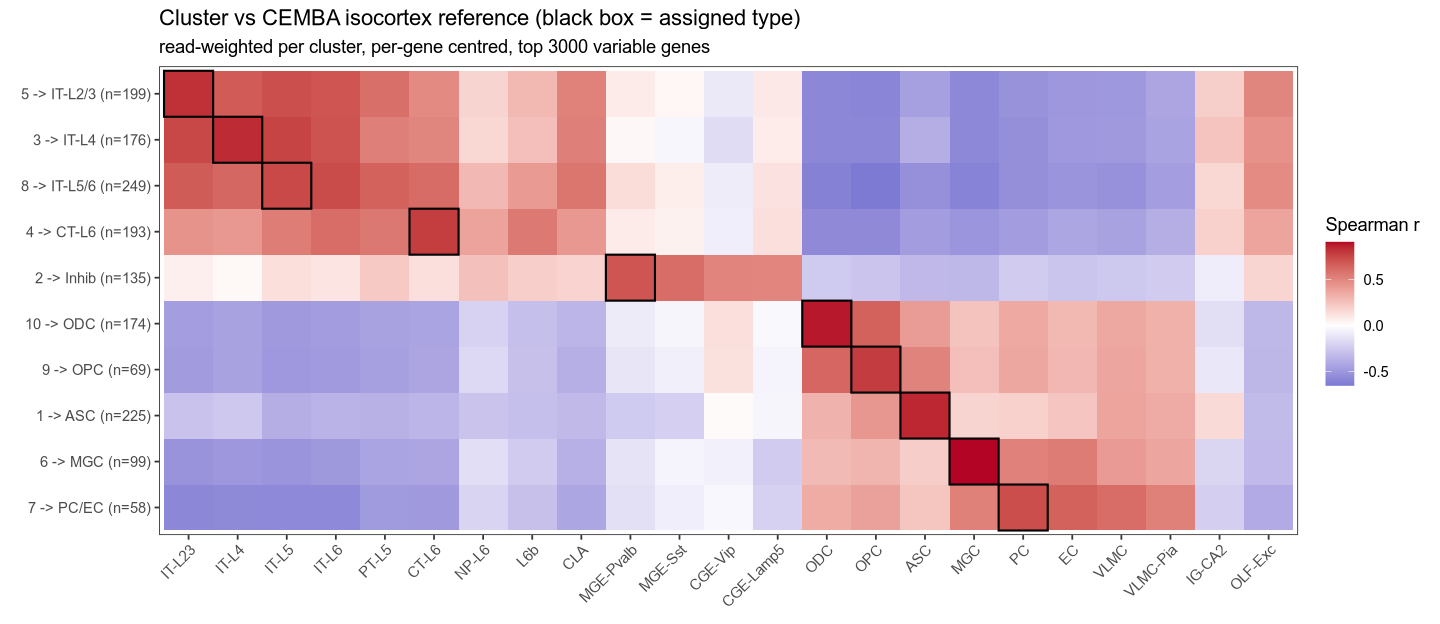

In [20]:
# §8c Final labels + the correlation shown as a heatmap.
# The random-forest outlier rescue that used to live here is GONE: plain Leiden
# assigns every cell, so there is nothing to rescue. One fewer moving part.
suppressPackageStartupMessages({ library(ggplot2); library(dplyr) })

# 10-type palette. Excitatory warm ramp by layer, one inhibitory magenta,
# non-neuronal greens/blues/yellow -- same scheme as the earlier 12-type
# version so figures stay visually comparable.
celltype_colors <- c(
  `IT-L2/3` = "#FF9A4C", `IT-L4` = "#E84C3D", `IT-L5/6` = "#8C4A2F",
  `CT-L6`   = "#B8321C", Inhib   = "#C452B0",
  ODC       = "#66C2A5", OPC     = "#1B9E77", ASC = "#4DA3FF",
  MGC       = "#FFD92F", `PC/EC` = "#A6D854")
cell_type_levels <- names(celltype_colors)
ct_order <- cell_type_levels

cl2type <- setNames(atlas_call$type, atlas_call$cluster)
submetadata$cell_type <- unname(cl2type[submetadata$leiden_cluster])
submetadata$cell_type_fct <- factor(submetadata$cell_type, levels = cell_type_levels)
submetadata$cluster_color <- unname(celltype_colors[submetadata$cell_type])
stopifnot(!any(is.na(submetadata$cell_type)))
cat(sprintf("%d cells -> %d cell types, 0 unassigned\n",
            nrow(submetadata), length(unique(submetadata$cell_type))))
print(table(submetadata$cell_type_fct))

# NOTE on the inhibitory group: it is 48 Pvalb + 85 Vip by the earlier
# annotation, i.e. Vip is the MAJORITY. It is named "Inhib", never "Pvalb" --
# the MGE-Pvalb arg-max only reflects that a merged inhibitory profile sits
# closest to MGE-Pvalb (margin 0.089 over MGE-Sst), not that these are Pvalb
# cells.

## --- the correlation itself, as a heatmap: clusters x atlas major types ---
atlas_order <- c("IT-L23","IT-L4","IT-L5","IT-L6","PT-L5","CT-L6","NP-L6","L6b",
                 "CLA","MGE-Pvalb","MGE-Sst","CGE-Vip","CGE-Lamp5",
                 "ODC","OPC","ASC","MGC","PC","EC","VLMC","VLMC-Pia")
ao  <- c(intersect(atlas_order, colnames(Ccor)), setdiff(colnames(Ccor), atlas_order))
cro <- atlas_call$cluster[order(match(atlas_call$type, cell_type_levels), -atlas_call$n)]
hm <- as.data.frame(as.table(Ccor[cro, ao, drop = FALSE]))
names(hm) <- c("cluster", "atlas", "r")
hm$cluster <- factor(hm$cluster, levels = rev(cro))
hm$atlas   <- factor(hm$atlas,   levels = ao)
lab <- atlas_call[match(cro, atlas_call$cluster), ]
hm$is_best <- paste(hm$cluster, hm$atlas) %in% paste(lab$cluster, lab$best)
ylab <- sprintf("%s -> %s (n=%d)", lab$cluster, lab$type, lab$n)
names(ylab) <- lab$cluster

options(repr.plot.width = 12, repr.plot.height = 5.2)
p_cor <- ggplot(hm, aes(atlas, cluster, fill = r)) +
  geom_tile() +
  geom_tile(data = subset(hm, is_best), colour = "black", linewidth = 0.6, fill = NA) +
  scale_fill_gradient2(low = "#3b4cc0", mid = "white", high = "#b40426",
                       midpoint = 0, name = "Spearman r") +
  scale_y_discrete(labels = ylab) +
  labs(title = "Cluster vs CEMBA isocortex reference (black box = assigned type)",
       subtitle = sprintf("read-weighted per cluster, per-gene centred, top %d variable genes",
                          length(hvg)),
       x = NULL, y = NULL) +
  theme_bw() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), panel.grid = element_blank())
print(p_cor)
ggsave_both(file.path(OUT_FIG, "atlas_correlation_heatmap"), p_cor, 12, 5.2)


In [21]:
# §8e Marker panel — the published markers from the reference atlas.
#
# Liu et al. 2021 Supplementary Table 7 ("Cell type annotations") lists five
# marker genes per major type, curated from the literature (Luo 2017, Tasic
# 2018, Zeisel 2018, Yao 2020). Using them rather than deriving our own removes
# the circularity of a panel selected on the same data it is then shown to fit:
# nothing about this gene list was chosen with reference to these cells.
#
# Each of our ten labels takes the block of the atlas type it corresponds to.
# For the merged labels that means choosing which member's block to show, and
# PRIMARY records the choice explicitly rather than burying it:
#   IT-L5/6 -> IT-L6      (IT-L5 and IT-L6 both map here; IT-L6 scores better)
#   CT-L6   -> CT-L6      (not the folded-in NP-L6, whose markers do not transfer)
#   Inhib   -> MGE-Pvalb  (of the four inhibitory blocks, the only one that holds)
#   PC/EC   -> PC         (rather than EC)
# Those four are choices made after seeing the data. They are legitimate for a
# descriptive panel but are NOT evidence; the unmerged six types have exactly one
# corresponding block each, so nothing is chosen for them.
#
# Expect an uneven panel. Glial and vascular blocks reproduce almost perfectly;
# the excitatory ones are weaker, and IT-L2/3 and IT-L5/6 largely fail. That is
# a property of the reference list -- in the CEMBA matrix itself IT-L23 scores
# 0/5 and IT-L5/IT-L6 2/5 and 1/5 -- not of this annotation. The printed tally
# below is the honest summary; read it rather than the colours, because
# scale = "column" shows rank within a gene, not effect size.
SUPP7 <- file.path(OUT_DIR, "cemba_ref", "supp_table7_marker_genes.tsv")
stopifnot(file.exists(SUPP7))
tb7 <- read.delim(SUPP7, stringsAsFactors = FALSE)
BLOCKS <- setNames(lapply(tb7$marker_genes,
                          function(x) trimws(strsplit(x, ",")[[1]])), tb7$major_type)
PRIMARY <- c(`IT-L2/3` = "IT-L23", `IT-L4` = "IT-L4", `IT-L5/6` = "IT-L6",
             `CT-L6` = "CT-L6", Inhib = "MGE-Pvalb", ODC = "ODC", OPC = "OPC",
             ASC = "ASC", MGC = "MGC", `PC/EC` = "PC")
ct_order <- cell_type_levels
stopifnot(setequal(names(PRIMARY), ct_order))

.mk  <- readRDS(file.path(WORKDIR, "QC", "methylation_matrices",
                          "HCG_gene_body_counts.rds"))
.cells <- intersect(rownames(submetadata), colnames(.mk$mc))
.grp   <- setNames(submetadata[.cells, "cell_type"], .cells)
.gg    <- rownames(.mk$mc)

# read-weighted pseudobulk, each type's own global rate subtracted -- global
# gene-body mCG spans ~7 points between types and scale = "column" does not
# remove it (per-gene centring shifts a gene by a constant)
.gmc <- colSums(.mk$mc [, .cells, drop = FALSE])
.gcv <- colSums(.mk$cov[, .cells, drop = FALSE])
.O <- t(sapply(ct_order, function(t) { ix <- names(.grp)[.grp == t]
  rowSums(.mk$mc[.gg, ix, drop = FALSE]) / rowSums(.mk$cov[.gg, ix, drop = FALSE]) -
    sum(.gmc[ix]) / sum(.gcv[ix]) }))
colnames(.O) <- .gg

marker_lists <- lapply(PRIMARY[ct_order], function(b) intersect(BLOCKS[[b]], .gg))
names(marker_lists) <- ct_order
marker_stats <- do.call(rbind, lapply(ct_order, function(k) {
  g <- marker_lists[[k]]; if (!length(g)) return(NULL)
  data.frame(cell_type = k, block = unname(PRIMARY[k]), gene = g,
             value  = round(.O[k, g], 3),
             rank   = sapply(g, function(x) rank(.O[, x])[match(k, ct_order)]),
             margin = round(sapply(g, function(x)
                        min(.O[setdiff(ct_order, k), x]) - .O[k, x]), 3),
             lowest_in = sapply(g, function(x) ct_order[which.min(.O[, x])]),
             cov = as.integer(rowSums(.mk$cov[g, names(.grp)[.grp == k], drop = FALSE])))
}))
rm(.mk); invisible(gc(verbose = FALSE))

cat(sprintf("published panel: %d genes over %d types\n\n",
            length(unlist(marker_lists)), length(marker_lists)))
print(marker_stats, row.names = FALSE)
cat("\n--- per-type tally: genes where this type IS the most hypomethylated ---\n")
for (k in ct_order) {
  r <- marker_stats[marker_stats$cell_type == k, ]
  cat(sprintf("  %-9s (%-9s) %d/%d rank 1, mean margin %+.3f\n",
              k, PRIMARY[[k]], sum(r$rank == 1), nrow(r), mean(r$margin)))
}
write.csv(marker_stats, file.path(OUT_TAB, "published_markers_supp7.csv"), row.names = FALSE)
cat("\nwrote tables/published_markers_supp7.csv\n")


published panel: 50 genes over 10 types



 cell_type     block     gene  value rank margin lowest_in   cov
   IT-L2/3    IT-L23    Prex1 -0.077    2 -0.013       ASC 21985
   IT-L2/3    IT-L23     Cux2 -0.152    2 -0.041     IT-L4 33581
   IT-L2/3    IT-L23  Rnf144a -0.097    1  0.000   IT-L2/3  9678
   IT-L2/3    IT-L23    Enpp2 -0.044    2 -0.080       ODC  8612
   IT-L2/3    IT-L23   Zfp462 -0.106    2 -0.014       OPC 16597
     IT-L4     IT-L4    Foxo3 -0.034    1  0.004     IT-L4 12589
     IT-L4     IT-L4     Rorb -0.254    1  0.187     IT-L4  9833
     IT-L4     IT-L4    Kcnh5 -0.208    1  0.216     IT-L4 11016
     IT-L4     IT-L4  Tspan11 -0.043    1  0.024     IT-L4  5503
     IT-L4     IT-L4   Cadps2  0.056    4 -0.063       MGC 25932
   IT-L5/6     IT-L6     Xkr7 -0.183    7 -0.079     CT-L6  6762
   IT-L5/6     IT-L6    Mgat5  0.010    2 -0.056   IT-L2/3 43623
   IT-L5/6     IT-L6    Susd4  0.028    1  0.004   IT-L5/6 27238
   IT-L5/6     IT-L6  Adamts3  0.026    3 -0.015       MGC 21441
   IT-L5/6     IT-L6    N


--- per-type tally: genes where this type IS the most hypomethylated ---


  IT-L2/3   (IT-L23   ) 1/5 rank 1, mean margin -0.030
  IT-L4     (IT-L4    ) 4/5 rank 1, mean margin +0.074
  IT-L5/6   (IT-L6    ) 1/5 rank 1, mean margin -0.031
  CT-L6     (CT-L6    ) 3/5 rank 1, mean margin +0.063
  Inhib     (MGE-Pvalb) 5/5 rank 1, mean margin +0.035
  ODC       (ODC      ) 4/5 rank 1, mean margin +0.209
  OPC       (OPC      ) 5/5 rank 1, mean margin +0.136
  ASC       (ASC      ) 5/5 rank 1, mean margin +0.168
  MGC       (MGC      ) 5/5 rank 1, mean margin +0.363
  PC/EC     (PC       ) 5/5 rank 1, mean margin +0.081



wrote tables/published_markers_supp7.csv


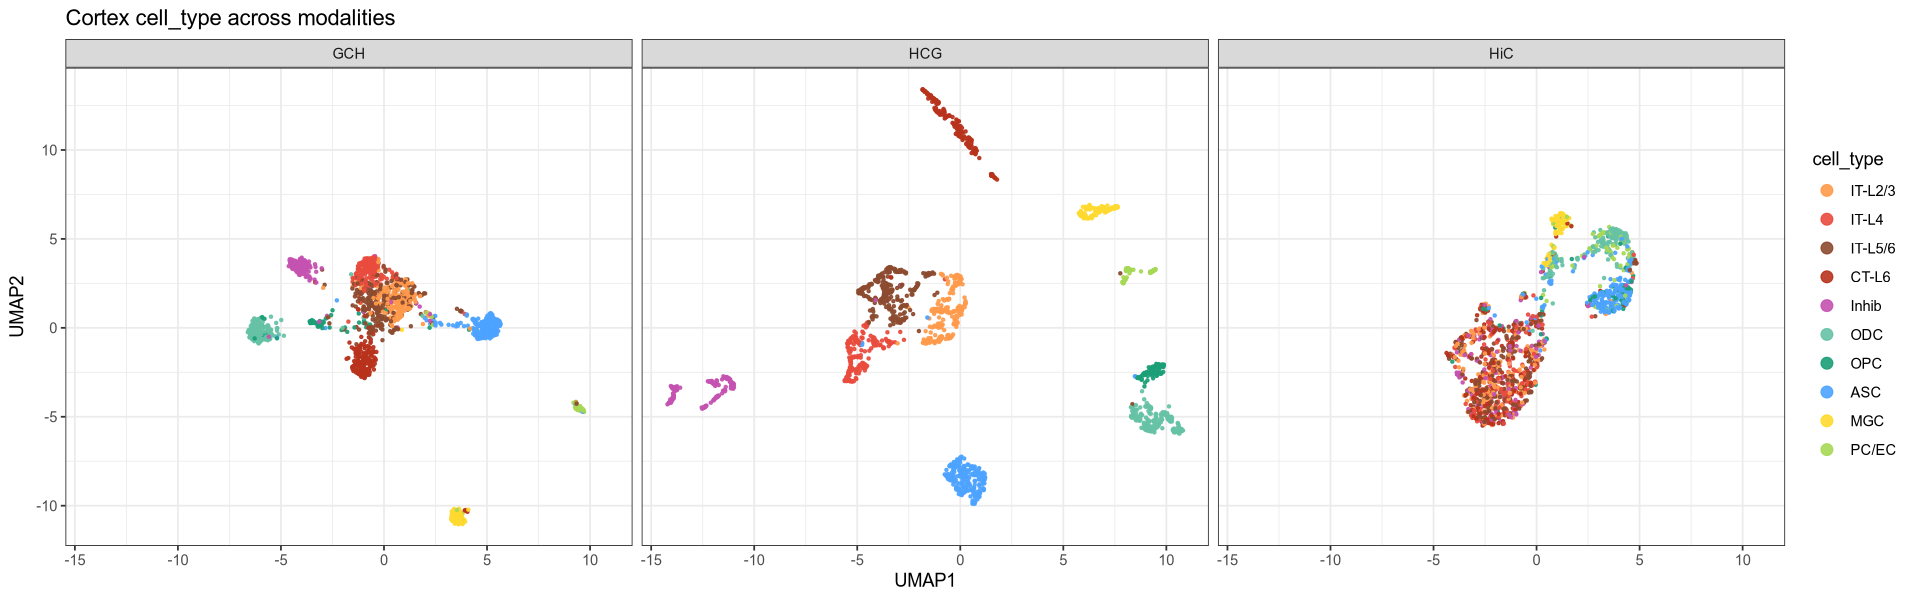

In [22]:
# §8f UMAPs colored by cell_type (HCG / GCH / HiC)
options(repr.plot.width = 16, repr.plot.height = 5)
ct_fct <- factor(submetadata$cell_type, levels = cell_type_levels)

make_ct_df <- function(layout, name) {
  data.frame(
    UMAP1 = layout[, 1], UMAP2 = layout[, 2],
    cell_type = ct_fct[match(rownames(layout), rownames(submetadata))],
    stringsAsFactors = FALSE
  ) %>% mutate(modality = name)
}
df_ct <- bind_rows(
  make_ct_df(HCG.umap$layout, "HCG"),
  make_ct_df(hic_umap$layout, "HiC"),
  make_ct_df(gch_umap$layout, "GCH")
)

p_ct <- ggplot(df_ct, aes(UMAP1, UMAP2, colour = cell_type)) +
  geom_point(size = 0.6, alpha = 0.9) +
  facet_wrap(~ modality, nrow = 1) +
  scale_color_manual(values = celltype_colors, na.value = "grey80") +
  guides(colour = guide_legend(override.aes = list(size = 3))) +
  labs(title = "Cortex cell_type across modalities") +
  theme_bw() + theme(legend.position = "right")
print(p_ct)
ggsave_both(file.path(OUT_FIG, "annotation_umaps_celltype"), p_ct, 16, 5)

## §8.5 Marker-gene heatmap (cortex)

Marker-gene methylation per cell type, drawn from **our own per-cell counts** —
`QC/methylation_matrices/HCG_<region>_counts.rds`, built by
`build_hcg_counts.R` — over **TSS + gene body** (the `gene` region: reads
from the TSS and the gene body pooled together). The TSS-only and
body-only variants are still computed and saved by §9b, but only this
region is plotted.
An earlier version of this section read a precomputed gene-level matrix; it now
computes the pseudobulk here so the estimator matches everything else in the
notebook.

**Pseudobulk is read-weighted**: `sum(mc)/sum(cov)` over each type's cells, never
a mean of per-cell rates, and each type's own global rate is subtracted before
plotting. That subtraction matters — global gene-body mCG spans ~7 percentage
points between types, and `scale = "column"` does not remove it, because
per-gene centring shifts a gene by a constant.

**Genes come from §8e**: the published markers of Liu et al. 2021 Supplementary
Table 7, one block per cell type. Nothing in the list was selected using these
data.

Read the panel by §8e's printed tally, not by how blue a block looks: column
scaling shows a type's *rank* within a gene, not the size of the difference.

wrote marker_gene_heatmap_HCG_gene.pdf (+png)  (10 cell types x 50 markers)


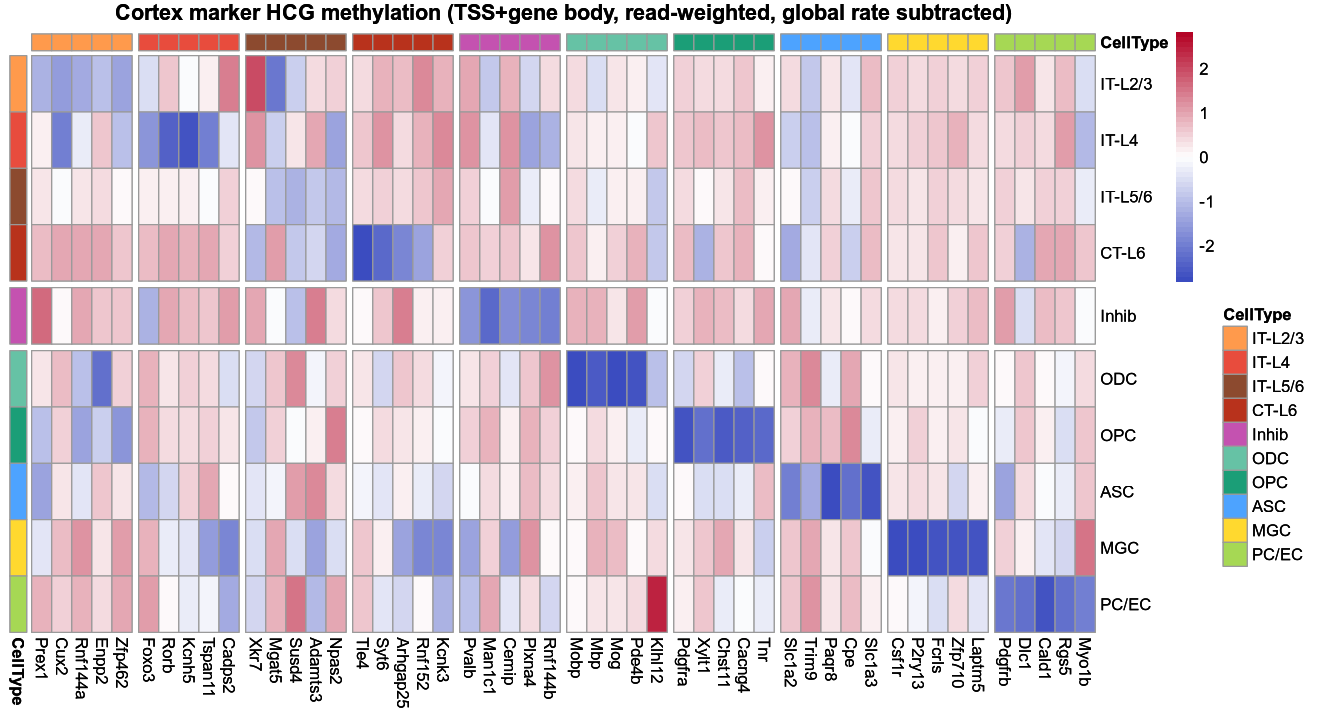

In [23]:
# §8.5 Marker-gene HCG methylation heatmaps — read-weighted pseudobulk
# Source: per-cell HCG methylated_reads / total_reads at three region
# resolutions (this replaced an earlier dependence on a precomputed matrix),
# precomputed by QC/methylation_matrices/build_hcg_counts.R into
#   HCG_<region>_counts.rds   (list of mc, cov : genes x cells).
# Pseudobulk per cell type is READ-WEIGHTED: sum(mc)/sum(cov) over the cells
# in that type (not a mean of per-cell fractions), so high-coverage cells
# contribute proportionally and no kNN imputation is needed.
suppressPackageStartupMessages({ library(pheatmap); library(grid) })

COUNTS_DIR <- file.path(WORKDIR, "QC", "methylation_matrices")
# region key -> label for titles/filenames
REGIONS <- c(gene = "TSS+gene body")   # TSS+gene body only, per the figure spec;
# HCG_gene_counts.rds / GCH_gene_counts.rds pool reads over the TSS and the
# gene body together. The TSS-only and body-only variants are still built by
# build_{hcg,gch}_counts.R and saved by §9b; they are simply not plotted.

## Marker panel comes from §8e: the PUBLISHED markers of Liu et al. 2021
## Supplementary Table 7, one block per cell type. Nothing in the gene list was
## chosen using these data, so the panel is not circular. Expect it to be uneven:
## the glial and vascular blocks reproduce strongly, IT-L2/3 and IT-L5/6 largely
## do not -- a property of the reference list, quantified in §8e's tally.
stopifnot(exists("marker_lists"), exists("ct_order"), length(ct_order) == 10)

# read-weighted pseudobulk (cell_type x marker_gene) for one region
pseudobulk_region <- function(region) {
  obj <- readRDS(file.path(COUNTS_DIR, sprintf("HCG_%s_counts.rds", region)))
  mc <- obj$mc; cov <- obj$cov                          # genes x cells
  present <- intersect(unlist(marker_lists), rownames(mc))
  ml  <- lapply(marker_lists, intersect, y = present)   # keep only present markers
  mg  <- unlist(ml)
  labeled <- intersect(colnames(mc),
                       rownames(submetadata)[!is.na(submetadata$cell_type)])
  grp <- split(labeled, submetadata[labeled, "cell_type"])
  # Global gene-body HCG differs by cell type by ~7 percentage points on this
  # annotation (Inhib 0.742 highest, PC/EC 0.671 lowest; neurons above glia).
  # Subtract each type's own global rate, matching how §8e scores the same genes
  # -- otherwise the table and the figure use different estimators.
  # scale = "column" does NOT fix this: per-gene centring shifts a gene by a
  # constant and leaves the per-cell-type offset untouched. Uncorrected, a
  # globally-hypomethylated type reads as marker-positive everywhere.
  glob <- sapply(grp, function(cc)
    sum(mc[, cc, drop = FALSE]) / sum(cov[, cc, drop = FALSE]))
  pb  <- t(sapply(grp, function(cc) {
    num <- rowSums(mc [mg, cc, drop = FALSE])
    den <- rowSums(cov[mg, cc, drop = FALSE])
    v <- num / den; v[den == 0] <- NA_real_; v
  }))                                                    # cell_type x marker_gene
  pb <- sweep(pb, 1, glob[rownames(pb)], "-")            # per-type mean subtraction
  ctp <- intersect(ct_order, rownames(pb))
  list(mat = pb[ctp, mg, drop = FALSE], ml = ml, mg = mg, ctp = ctp)
}

# Build the pseudobulk matrix + pheatmap argument list for one region (no plotting).
build_region_heat <- function(region, label) {
  r   <- pseudobulk_region(region)
  g2t <- rep(names(r$ml), lengths(r$ml)); names(g2t) <- r$mg
  ann_col <- data.frame(CellType = factor(g2t[r$mg], levels = names(marker_lists)),
                        row.names = r$mg)
  ann_row <- data.frame(CellType = factor(r$ctp, levels = names(marker_lists)),
                        row.names = r$ctp)
  ann_colors <- list(CellType = celltype_colors[levels(ann_col$CellType)])
  # Lineage groups for the row dividers. Must list ALL excitatory types, or the
  # Exc | Inh | Non-neuron gaps land on the wrong rows.
  exc <- c("IT-L2/3","IT-L4","IT-L5/6","CT-L6"); inh <- "Inhib"
  gaps_row <- c(sum(r$ctp %in% exc), sum(r$ctp %in% c(exc, inh)))
  gaps_col <- cumsum(lengths(r$ml))[seq_len(length(r$ml) - 1)]
  args <- list(
    mat = r$mat, cluster_rows = FALSE, cluster_cols = FALSE,
    annotation_col = ann_col, annotation_row = ann_row,
    annotation_colors = ann_colors, gaps_row = gaps_row, gaps_col = gaps_col,
    scale = "column", color = colorRampPalette(c("#3b4cc0","white","#b40426"))(50),
    main = sprintf("Cortex marker HCG methylation (%s, read-weighted, global rate subtracted)", label))
  c(r, list(args = args,
            out_pdf = file.path(OUT_FIG, sprintf("marker_gene_heatmap_HCG_%s.pdf", region))))
}

options(repr.plot.width = 11, repr.plot.height = 6)

# 1) Build pseudobulk + heatmap args for every region (no plotting yet).
hcg_marker_pb <- list()
for (region in names(REGIONS))
  hcg_marker_pb[[region]] <- build_region_heat(region, REGIONS[[region]])

# 2) Inline render for the notebook FIRST. pheatmap with no filename draws to the
#    current device. This MUST run BEFORE the filename= writes below: writing a file
#    opens AND closes pheatmap's own graphics device, which disables inline display
#    for the rest of the cell. So draw to the notebook first, then write the files.
for (region in names(REGIONS)) print(do.call(pheatmap, hcg_marker_pb[[region]]$args))

# 3) Write each PDF + PNG via pheatmap's own `filename=` argument. pheatmap opens
#    AND closes its own graphics device internally and correctly, so the write is
#    robust even if other graphics devices are open in the session (e.g. a stale
#    device left by an earlier crashed run). Hand-rolled pdf()/dev.off() around
#    pheatmap is fragile here — that produced the earlier truncated gene_tss.pdf.
for (region in names(REGIONS)) {
  a <- hcg_marker_pb[[region]]
  for (ext in c("pdf", "png"))
    do.call(pheatmap, c(a$args, list(filename = sub("\\.pdf$", paste0(".", ext), a$out_pdf), width = 11, height = 6)))
  cat(sprintf("wrote %s (+png)  (%d cell types x %d markers)\n",
              basename(a$out_pdf), nrow(a$args$mat), ncol(a$args$mat)))
}


## §8.5b Marker-gene accessibility heatmap (GCH, TSS + gene body)

Mirrors §8.5 — same cell-type order, same lineage row/column gaps, same
read-weighted pseudobulk and per-type global-rate subtraction — but reads
chromatin **accessibility** from `QC/methylation_matrices/GCH_gene_counts.rds`
over the **TSS + gene body** region.

**Same gene panel as §8.5**: the published markers of Liu et al. 2021
Supplementary Table 7, taken from §8e's `marker_lists`. Using one panel across
both modalities makes the two figures gene-for-gene comparable.

**The sign flips.** An HCG marker is *hypo*methylated in its own type (low,
blue in §8.5); a GCH marker is *more accessible* (high, red here). The diagonal
reads bright in this panel and dark in §8.5.

GCH took no part in the clustering, the atlas assignment, or the gene
selection, so this panel is an independent check on the annotation rather than
a restatement of it.

wrote marker_gene_heatmap_GCH_gene.pdf (+png)  (10 cell types x 50 markers)


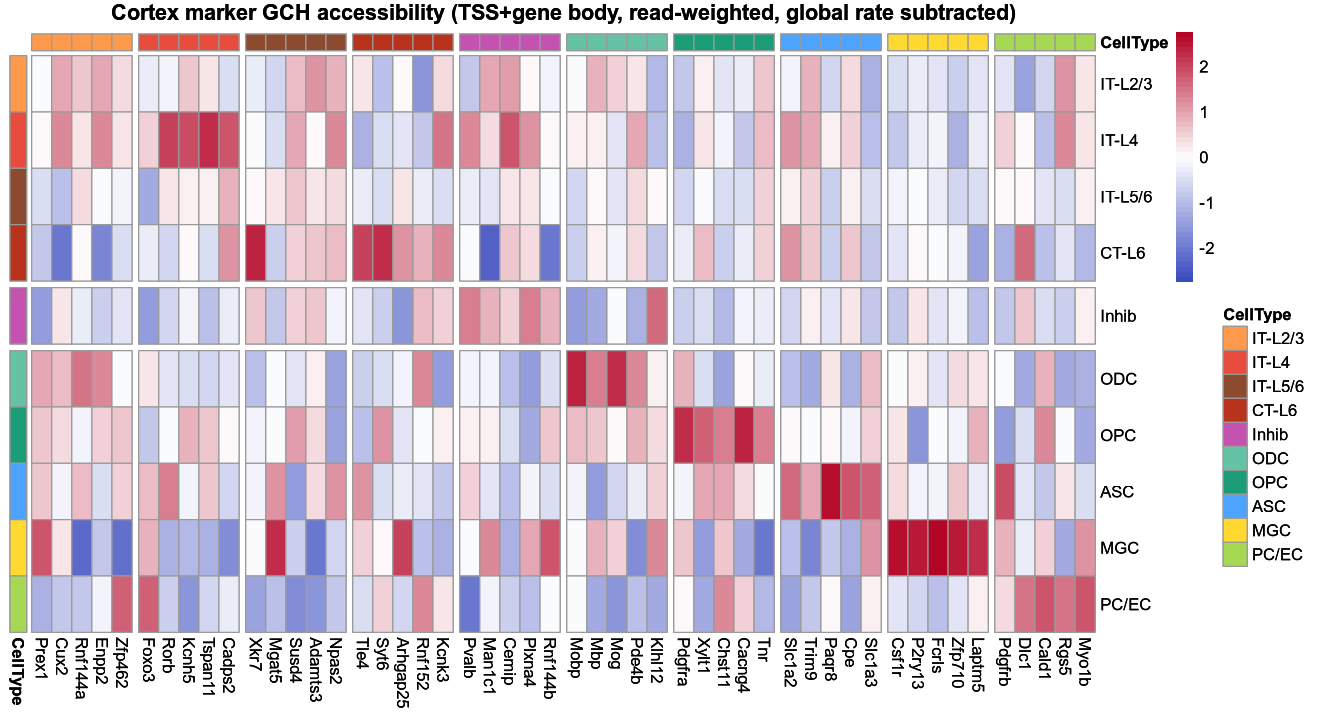

In [24]:
# §8.5b Marker-gene GCH accessibility heatmaps — read-weighted pseudobulk
# GCH methylation = chromatin ACCESSIBILITY. Pseudobulk per cell type is
# READ-WEIGHTED: sum(accessible_reads)/sum(coverage) over the cells of a type
# (NOT a mean of per-cell rates), matching the HCG §8.5 method. Source = per-cell
# GCH counts precomputed by QC/methylation_matrices/build_gch_counts.R into
#   GCH_<region>_counts.rds   (list of mc=accessible, cov=coverage : genes x cells).
# Accessibility markers are ACTIVE genes, so the own-cell-type block is HIGH
# (accessible, red) here -- opposite to the hypomethylated HCG block in §8.5.
suppressPackageStartupMessages({ library(pheatmap); library(grid) })
stopifnot(exists("ct_order"), exists("celltype_colors"))

GCH_COUNTS_DIR <- file.path(WORKDIR, "QC", "methylation_matrices")
REGIONS_GCH <- c(gene = "TSS+gene body")   # TSS+gene body only, per the figure spec;
# HCG_gene_counts.rds / GCH_gene_counts.rds pool reads over the TSS and the
# gene body together. The TSS-only and body-only variants are still built by
# build_{hcg,gch}_counts.R and saved by §9b; they are simply not plotted.

# Uses exactly the same published panel as §8.5 (Supp Table 7 via §8e), so the
# two heatmaps are gene-for-gene comparable across modalities. GCH took no part
# in the annotation or in the gene selection, so this is an independent check.
# NOTE the sign flips: an HCG marker is HYPOmethylated (low, blue); a GCH marker
# is MORE ACCESSIBLE (high, red). The diagonal therefore reads red here.
marker_lists_gch <- marker_lists

# read-weighted accessibility pseudobulk (cell_type x marker_gene) for one region
pseudobulk_gch <- function(region) {
  obj <- readRDS(file.path(GCH_COUNTS_DIR, sprintf("GCH_%s_counts.rds", region)))
  mc <- obj$mc; cov <- obj$cov                          # accessible, coverage : genes x cells
  present <- intersect(unlist(marker_lists_gch), rownames(mc))
  ml  <- lapply(marker_lists_gch, intersect, y = present)
  mg  <- unlist(ml)
  labeled <- intersect(colnames(mc),
                       rownames(submetadata)[!is.na(submetadata$cell_type)])
  grp <- split(labeled, submetadata[labeled, "cell_type"])
  # Global GCH accessibility differs by cell type by ~7 percentage points
  # (IT-L5/6 0.6745 highest, ODC 0.6077 lowest). Subtract each type's own global
  # rate, exactly as §8.5 and §8.5c do. scale = "column" does NOT remove it:
  # per-gene centring shifts a gene by a constant and leaves the per-type offset
  # intact. Uncorrected, globally-accessible types read as marker-positive
  # everywhere -- uncorrected, a globally-accessible type reads as
  # marker-positive across the whole panel.
  glob <- sapply(grp, function(cc)
    sum(mc[, cc, drop = FALSE]) / sum(cov[, cc, drop = FALSE]))
  pb  <- t(sapply(grp, function(cc) {
    num <- rowSums(mc [mg, cc, drop = FALSE])
    den <- rowSums(cov[mg, cc, drop = FALSE])
    v <- num / den; v[den == 0] <- NA_real_; v
  }))
  pb <- sweep(pb, 1, glob[rownames(pb)], "-")            # per-type mean subtraction                                                    # cell_type x marker_gene
  ctp <- intersect(ct_order, rownames(pb))
  list(mat = pb[ctp, mg, drop = FALSE], ml = ml, mg = mg, ctp = ctp)
}

build_gch_heat <- function(region, label) {
  r   <- pseudobulk_gch(region)
  g2t <- rep(names(r$ml), lengths(r$ml)); names(g2t) <- r$mg
  ann_col <- data.frame(CellType = factor(g2t[r$mg], levels = names(marker_lists_gch)),
                        row.names = r$mg)
  ann_row <- data.frame(CellType = factor(r$ctp, levels = names(marker_lists_gch)),
                        row.names = r$ctp)
  ann_colors <- list(CellType = celltype_colors[levels(ann_col$CellType)])
  # Lineage groups for the row dividers. Must list ALL excitatory types, or the
  # Exc | Inh | Non-neuron gaps land on the wrong rows.
  exc <- c("IT-L2/3","IT-L4","IT-L5/6","CT-L6"); inh <- "Inhib"
  gaps_row <- c(sum(r$ctp %in% exc), sum(r$ctp %in% c(exc, inh)))
  gaps_col <- cumsum(lengths(r$ml))[seq_len(length(r$ml) - 1)]
  args <- list(
    mat = r$mat, cluster_rows = FALSE, cluster_cols = FALSE,
    annotation_col = ann_col, annotation_row = ann_row,
    annotation_colors = ann_colors, gaps_row = gaps_row, gaps_col = gaps_col,
    scale = "column", color = colorRampPalette(c("#3b4cc0","white","#b40426"))(50),
    main = sprintf("Cortex marker GCH accessibility (%s, read-weighted, global rate subtracted)", label))
  c(r, list(args = args,
            out_pdf = file.path(OUT_FIG, sprintf("marker_gene_heatmap_GCH_%s.pdf", region))))
}

options(repr.plot.width = 11, repr.plot.height = 6)

# 1) build pseudobulk + args for every region (no plotting)
gch_marker_pb <- list()
for (region in names(REGIONS_GCH))
  gch_marker_pb[[region]] <- build_gch_heat(region, REGIONS_GCH[[region]])

# 2) inline render FIRST — pheatmap(filename=) below closes its own device and
#    disables inline display for the rest of the cell, so draw to the notebook first
for (region in names(REGIONS_GCH)) print(do.call(pheatmap, gch_marker_pb[[region]]$args))

# 3) write each PDF + PNG via pheatmap's own filename= (robust to other open devices)
for (region in names(REGIONS_GCH)) {
  a <- gch_marker_pb[[region]]
  for (ext in c("pdf", "png"))
    do.call(pheatmap, c(a$args, list(filename = sub("\\.pdf$", paste0(".", ext), a$out_pdf), width = 11, height = 6)))
  cat(sprintf("wrote %s (+png)  (%d cell types x %d markers)\n",
              basename(a$out_pdf), nrow(a$args$mat), ncol(a$args$mat)))
}


wrote marker_gene_heatmap_GCH_gene_ctmeansub.pdf (+png)  (10 cell types x 50 markers)


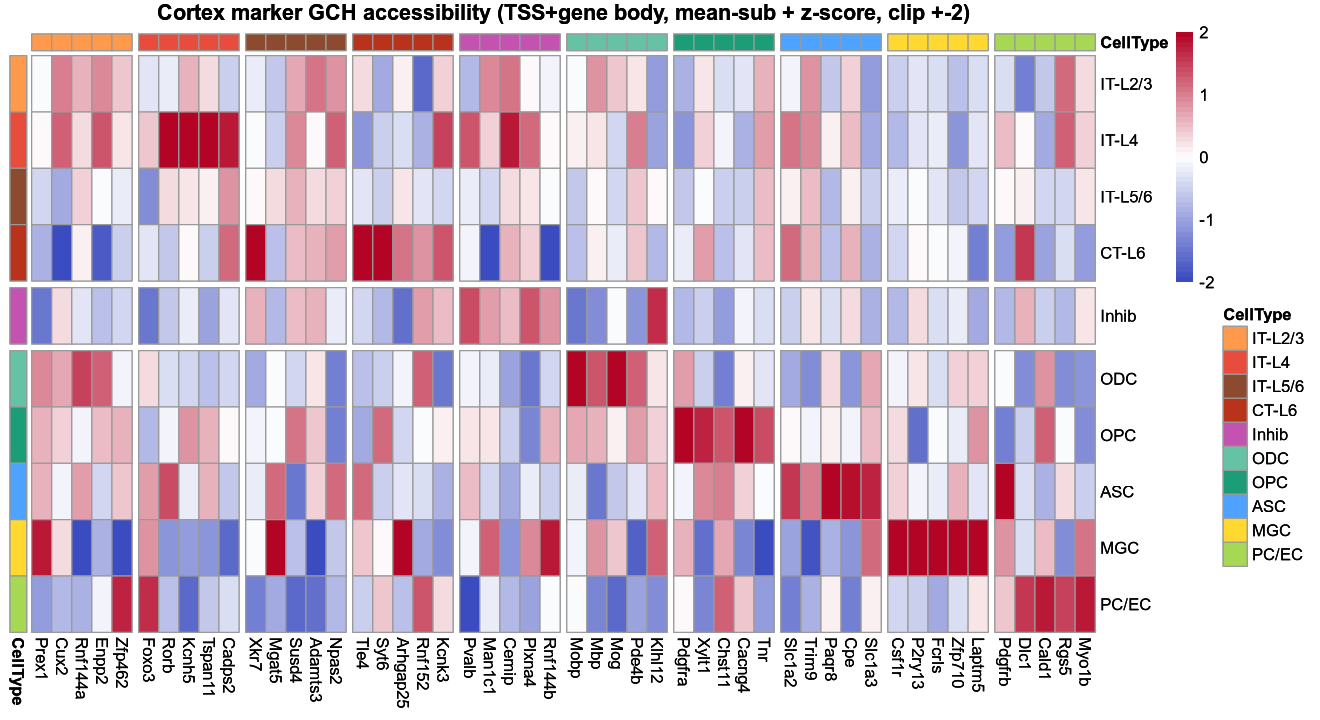

In [25]:
# §8.5c Marker-gene GCH accessibility heatmaps — NORMALISED (mean-sub + z-score + clip)
# Proper marker-heatmap normalization, in three steps:
#   1. mean-subtract: from each marker value subtract that cell type's READ-WEIGHTED
#      global rate G[ct] = sum(accessible over ALL genes)/sum(cov). Removes the
#      per-cell-type global offset (else globally-high types like IT-L4 / PC-EC read
#      red across nearly all markers). This is the pooled-level analogue of ALLCools'
#      per-cell global-rate normalization, consistent with read-weighted pooling.
#   2. z-score per GENE (column): standardises each gene so its winning cell type is
#      red regardless of the gene's absolute accessibility. Without this, a gene that
#      is globally low (e.g. Foxp2) looks blue everywhere even where its own type wins.
#   3. CLIP at +-ZCLIP: a few outlier cells (z up to ~2.8) otherwise stretch the colour
#      scale and wash everything out; clipping lets typical cells use the full range.
# (This is essentially what Seurat's DoHeatmap does: scaled + clipped.) Saved under a
# distinct name (..._ctmeansub) so the raw §8.5b heatmaps are preserved for compare.
suppressPackageStartupMessages({ library(pheatmap); library(grid) })
stopifnot(exists("ct_order"), exists("celltype_colors"),
          exists("marker_lists_gch"), exists("REGIONS_GCH"), exists("GCH_COUNTS_DIR"))

ZCLIP <- 2   # clip z-scores to +-ZCLIP so a few outliers don't wash out the colour scale

# read-weighted pseudobulk, mean-subtracted, then z-scored per gene and clipped
pseudobulk_gch_sub <- function(region) {
  obj <- readRDS(file.path(GCH_COUNTS_DIR, sprintf("GCH_%s_counts.rds", region)))
  mc <- obj$mc; cov <- obj$cov
  present <- intersect(unlist(marker_lists_gch), rownames(mc))
  ml  <- lapply(marker_lists_gch, intersect, y = present); mg <- unlist(ml)
  labeled <- intersect(colnames(mc),
                       rownames(submetadata)[!is.na(submetadata$cell_type)])
  grp <- split(labeled, submetadata[labeled, "cell_type"])
  pb  <- t(sapply(grp, function(cc) {
    num <- rowSums(mc [mg, cc, drop = FALSE])
    den <- rowSums(cov[mg, cc, drop = FALSE])
    v <- num / den; v[den == 0] <- NA_real_; v
  }))
  G   <- sapply(grp, function(cc) sum(mc[, cc]) / sum(cov[, cc]))   # global rate (ALL genes), per type
  ctp <- intersect(ct_order, rownames(pb))
  resid <- sweep(pb[ctp, mg, drop = FALSE], 1, G[ctp], "-")         # 1) mean-subtract
  z <- scale(resid)                                                 # 2) z-score per gene (column)
  z[is.nan(z)] <- 0                                                 # constant gene -> 0
  z <- pmax(pmin(z, ZCLIP), -ZCLIP)                                 # 3) clip
  dimnames(z) <- dimnames(resid)
  list(mat = z, resid = resid, ml = ml, mg = mg, ctp = ctp, G = G[ctp])
}

build_gch_sub_heat <- function(region, label) {
  r   <- pseudobulk_gch_sub(region)
  g2t <- rep(names(r$ml), lengths(r$ml)); names(g2t) <- r$mg
  ann_col <- data.frame(CellType = factor(g2t[r$mg], levels = names(marker_lists_gch)),
                        row.names = r$mg)
  ann_row <- data.frame(CellType = factor(r$ctp, levels = names(marker_lists_gch)),
                        row.names = r$ctp)
  ann_colors <- list(CellType = celltype_colors[levels(ann_col$CellType)])
  # Lineage groups for the row dividers. Must list ALL excitatory types, or the
  # Exc | Inh | Non-neuron gaps land on the wrong rows.
  exc <- c("IT-L2/3","IT-L4","IT-L5/6","CT-L6"); inh <- "Inhib"
  gaps_row <- c(sum(r$ctp %in% exc), sum(r$ctp %in% c(exc, inh)))
  gaps_col <- cumsum(lengths(r$ml))[seq_len(length(r$ml) - 1)]
  args <- list(
    mat = r$mat, cluster_rows = FALSE, cluster_cols = FALSE,
    annotation_col = ann_col, annotation_row = ann_row,
    annotation_colors = ann_colors, gaps_row = gaps_row, gaps_col = gaps_col,
    scale = "none", breaks = seq(-ZCLIP, ZCLIP, length.out = 51),
    color = colorRampPalette(c("#3b4cc0","white","#b40426"))(50),
    main = sprintf("Cortex marker GCH accessibility (%s, mean-sub + z-score, clip +-%g)", label, ZCLIP))
  c(r, list(args = args,
            out_pdf = file.path(OUT_FIG, sprintf("marker_gene_heatmap_GCH_%s_ctmeansub.pdf", region))))
}

options(repr.plot.width = 11, repr.plot.height = 6)
gch_marker_pb_sub <- list()
for (region in names(REGIONS_GCH))
  gch_marker_pb_sub[[region]] <- build_gch_sub_heat(region, REGIONS_GCH[[region]])

# inline render FIRST — pheatmap(filename=) below closes its own device and
# disables inline display for the rest of the cell, so draw to the notebook first
for (region in names(REGIONS_GCH)) print(do.call(pheatmap, gch_marker_pb_sub[[region]]$args))

for (region in names(REGIONS_GCH)) {
  a <- gch_marker_pb_sub[[region]]
  for (ext in c("pdf", "png"))
    do.call(pheatmap, c(a$args, list(filename = sub("\\.pdf$", paste0(".", ext), a$out_pdf),
                                    width = 11, height = 6)))
  cat(sprintf("wrote %s (+png)  (%d cell types x %d markers)\n",
              basename(a$out_pdf), nrow(a$args$mat), ncol(a$args$mat)))
}


## §8.7 Joint embedding across modalities (shared UMAP)

Per-modality Harmony-corrected embeddings (HCG top-9, Hi-C top-10, GCH
top-20 — matching the locked clustering dims in §4b/§5a/§6c) are z-scored
column-wise, concatenated along features, decorrelated via PCA (keeps all
9+10+20 = 39 components), then UMAP'd with the same
`(n_neighbors = 10, min_dist = 0.2)` settings used by the cell-line
notebook so the joint UMAP is comparable across pipelines.

In [26]:
# §8.7a Joint embedding: concat per-modality embeddings -> PCA (keep all 39) -> UMAP
hcg_emb <- HCG.harmony[, seq_len(9),  drop = FALSE]   # Harmony, top-9
hic_emb <- hic_harmony[, seq_len(10), drop = FALSE]   # Harmony, top-10
gch_emb <- gch_harmony[, seq_len(20), drop = FALSE]   # Harmony, top-20

shared <- Reduce(intersect, list(rownames(hcg_emb), rownames(hic_emb), rownames(gch_emb)))
cat("Cells in all 3 modalities:", length(shared), "\n")
hcg_emb <- hcg_emb[shared, , drop = FALSE]
hic_emb <- hic_emb[shared, , drop = FALSE]
gch_emb <- gch_emb[shared, , drop = FALSE]

# Z-score per column, then concatenate features.
hcg_std <- scale(hcg_emb)
hic_std <- scale(hic_emb)
gch_std <- scale(gch_emb)
joint_concat <- cbind(hcg_std, hic_std, gch_std)
colnames(joint_concat) <- c(paste0("HCG", seq_len(ncol(hcg_std))),
                            paste0("HiC", seq_len(ncol(hic_std))),
                            paste0("GCH", seq_len(ncol(gch_std))))
cat("Joint concat dims:", dim(joint_concat), "\n")

# PCA — keep all components (HCG 9 + HiC 10 + GCH 20 = 39 features, so PCA
# here is a decorrelating rotation rather than a dimensionality reduction).
n_keep    <- ncol(joint_concat)
joint_pca <- prcomp(joint_concat, center = FALSE, scale. = FALSE)$x[, seq_len(n_keep), drop = FALSE]
cat("Joint PCA dims:", dim(joint_pca), "\n")

# UMAP — settings mirror the cell-line joint_embedding.ipynb
umap_cfg <- umap::umap.defaults
umap_cfg$n_neighbors  <- 10
umap_cfg$min_dist     <- 0.2
umap_cfg$metric       <- "euclidean"
umap_cfg$random_state <- 42
set.seed(42)
joint_umap <- umap::umap(joint_pca, config = umap_cfg)
rownames(joint_umap$layout) <- shared

write.table(joint_pca,         file.path(OUT_TAB, "joint_embedding.txt"), sep = "\t", quote = FALSE)
write.table(joint_umap$layout, file.path(OUT_TAB, "joint_umap.txt"),       sep = "\t", quote = FALSE)


Cells in all 3 modalities: 1577 


Joint concat dims: 1577 39 


Joint PCA dims: 1577 39 


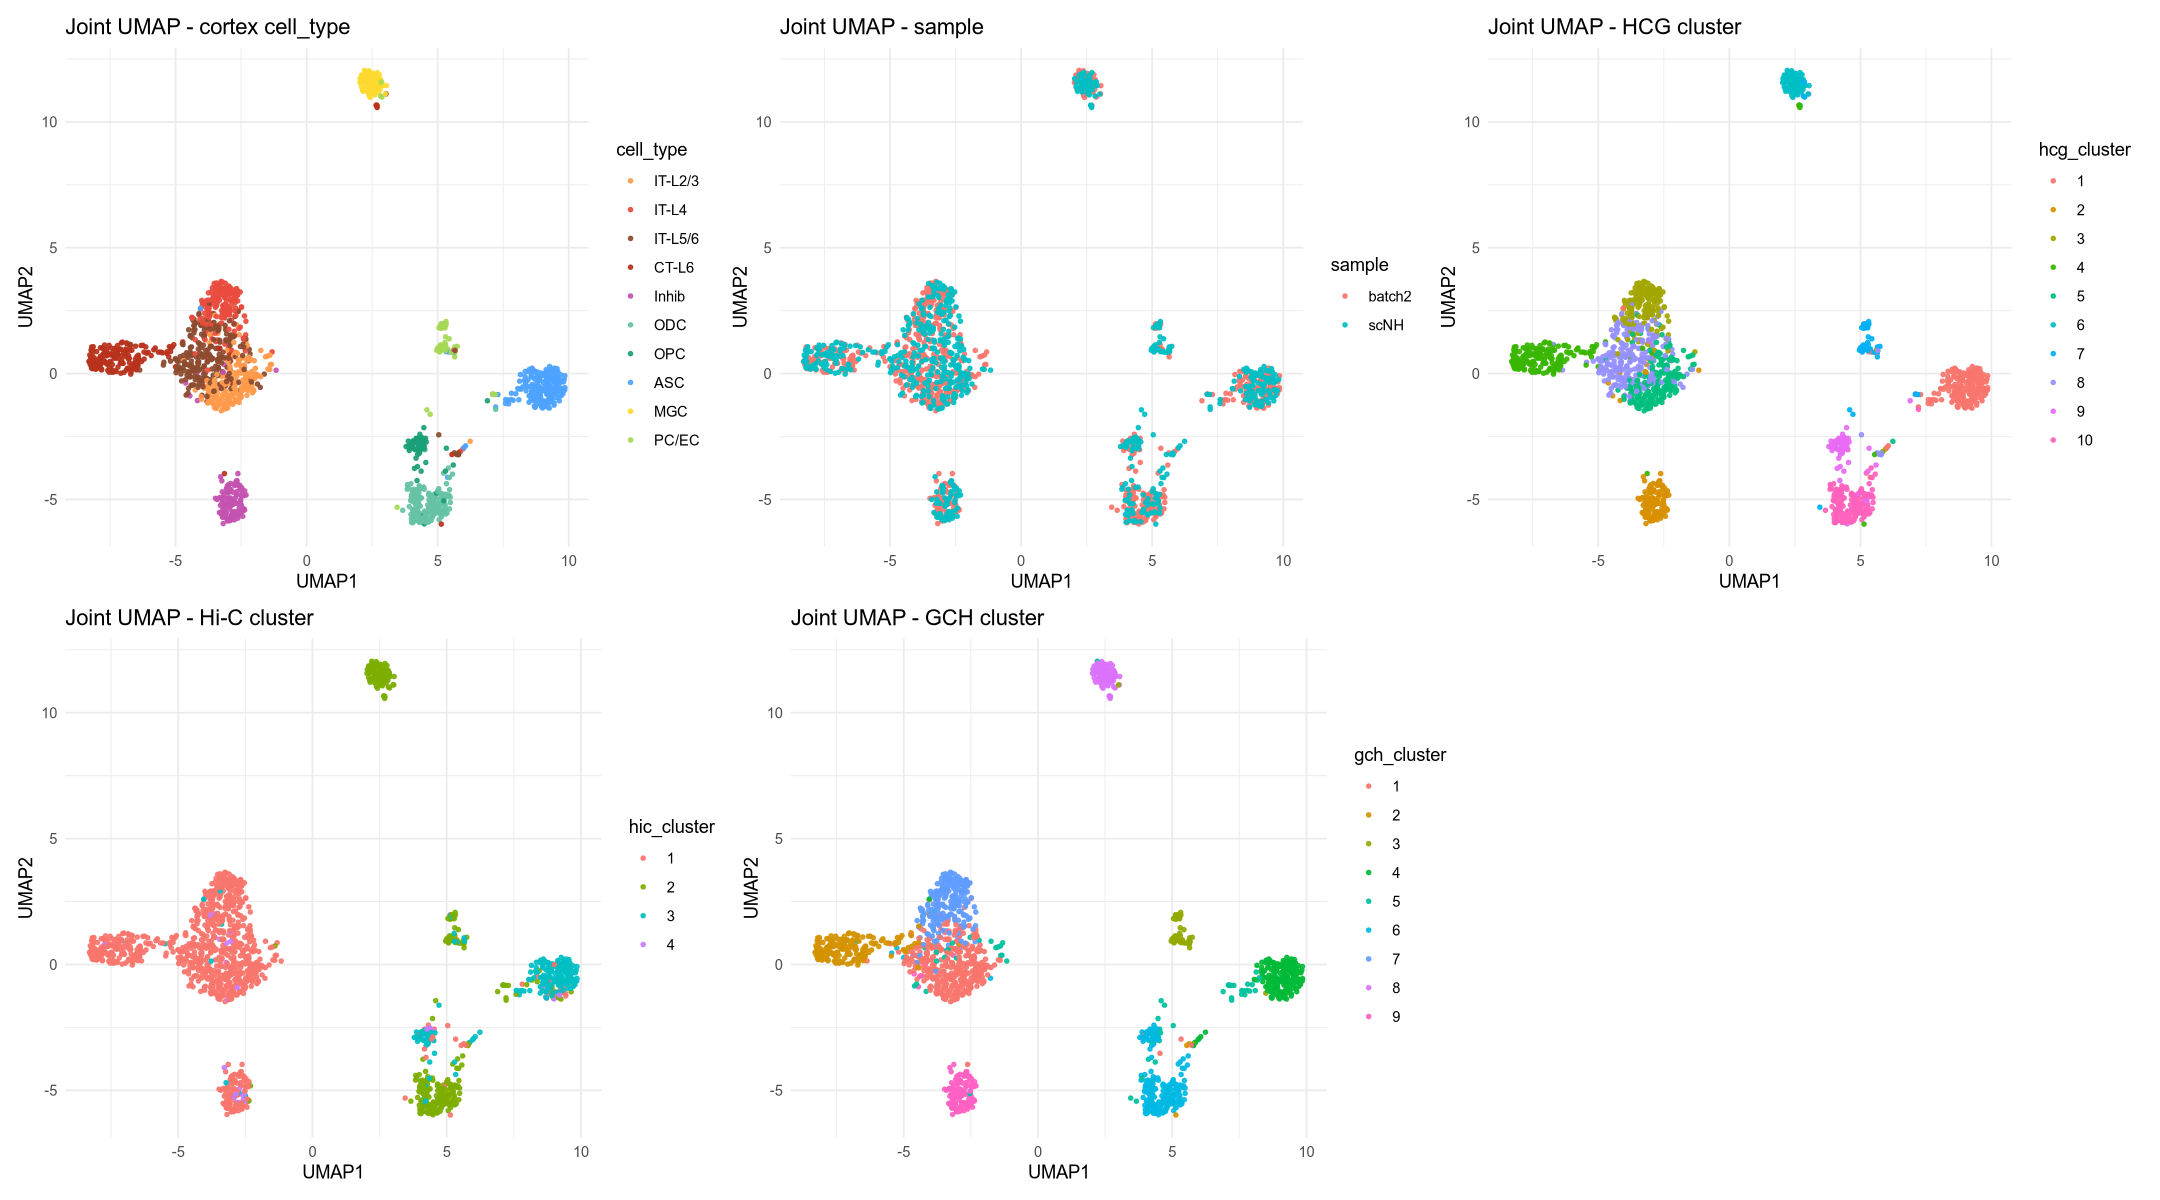

In [27]:
options(repr.plot.width = 18, repr.plot.height = 10)
# §8.7b Visualize joint UMAP — cell_type + sample + per-modality Leiden
df_joint <- data.frame(
  cell  = shared,
  UMAP1 = joint_umap$layout[, 1],
  UMAP2 = joint_umap$layout[, 2],
  cell_type   = factor(submetadata[shared, "cell_type"], levels = names(celltype_colors)),
  sample      = submetadata[shared, "sample"],
  hcg_cluster = factor(submetadata[shared, "hcg_cluster"]),
  hic_cluster = factor(submetadata[shared, "hic_cluster"]),
  gch_cluster = factor(submetadata[shared, "gch_cluster"]),
  stringsAsFactors = FALSE)

mk <- function(df, col, title)
  ggplot(df, aes(UMAP1, UMAP2, colour = .data[[col]])) +
    geom_point(size = 0.9, alpha = 0.9) + ggtitle(title) +
    theme_minimal(base_size = 11) + theme(legend.position = "right")

p_ct  <- mk(df_joint, "cell_type",   "Joint UMAP - cortex cell_type") +
         scale_color_manual(values = celltype_colors, na.value = "grey80")
p_b   <- mk(df_joint, "sample",      "Joint UMAP - sample")
p_hcg <- mk(df_joint, "hcg_cluster", "Joint UMAP - HCG cluster")
p_hic <- mk(df_joint, "hic_cluster", "Joint UMAP - Hi-C cluster")
p_gch <- mk(df_joint, "gch_cluster", "Joint UMAP - GCH cluster")

joint_panel <- (p_ct | p_b | p_hcg) / (p_hic | p_gch | patchwork::plot_spacer())
ggsave_both(file.path(OUT_FIG, "joint_umap"), joint_panel, 18, 10)
joint_panel


## §8.7c QC / batch diagnostic panels on the integrated UMAP

Colour the joint (integrated) UMAP by technical / batch covariates, to show the
embedding is driven by biology rather than batch:

- **A. Biological replicate** (`batch1` = scNH, `batch2`) — **before AND after**
  Harmony batch-effect correction. Before = a joint UMAP rebuilt from the raw
  per-modality SVD embeddings (§8.7c.1); after = the §8.7a Harmony-based UMAP.
- **B. Library-preparation batch** — `library_prep_date` from the two `snakemake/*_libprep_info.xlsx` sample sheets (covers 1576/1577 cells; `metadata.txt` only had 1143).
- **C. Uniquely aligned reads** — log10(`mapq30num`).
- **D. Percentage of aligned reads** — `mapq30rate` (MAPQ30).
- **E. Bisulfite incomplete conversion rate** — raw chrM non-CpG methylation (`noncpg_chrM`).
- **F. Percentage of cis reads** — `cisnum / (cisnum + transnum) × 100`.

In [28]:
# §8.7c.1 Uncorrected (pre-Harmony) joint embedding = the "before batch correction"
# half of panel A. Same recipe as §8.7a but on the RAW per-modality SVD embeddings
# (HCG top-9, Hi-C top-10, GCH top-20), with NO Harmony.
# Resume-friendly: use the in-session SVD objects if a full §4-§6 run is loaded,
# otherwise read the saved intermediates written by §4a/§5a/§6b.
rd_tab <- function(f) as.matrix(read.table(file.path(OUT_TAB, f), header = TRUE,
                                           row.names = 1, check.names = FALSE))
hcg_raw <- if (exists("HCG.svd")) HCG.svd[, seq_len(9),  drop = FALSE] else rd_tab("hcg_svd_raw.txt")
hic_raw <- if (exists("hic_mat")) hic_mat[, seq_len(10), drop = FALSE] else rd_tab("hic_svd_raw.txt")
gch_raw <- if (exists("gch_svd")) gch_svd[, seq_len(20), drop = FALSE] else rd_tab("gch_svd_raw.txt")

shared_u <- Reduce(intersect, list(rownames(hcg_raw), rownames(hic_raw), rownames(gch_raw)))
cat("Uncorrected joint cells:", length(shared_u), "\n")

jc <- cbind(scale(hcg_raw[shared_u, , drop = FALSE]),
            scale(hic_raw[shared_u, , drop = FALSE]),
            scale(gch_raw[shared_u, , drop = FALSE]))
jp <- prcomp(jc, center = FALSE, scale. = FALSE)$x            # decorrelating rotation

ucfg <- umap::umap.defaults
ucfg$n_neighbors  <- 10
ucfg$min_dist     <- 0.2
ucfg$metric       <- "euclidean"
ucfg$random_state <- 42
set.seed(42)
joint_umap_uncorr <- umap::umap(jp, config = ucfg)
rownames(joint_umap_uncorr$layout) <- shared_u
write.table(joint_umap_uncorr$layout, file.path(OUT_TAB, "joint_umap_uncorrected.txt"),
            sep = "\t", quote = FALSE)
cat("uncorrected joint UMAP:", dim(joint_umap_uncorr$layout), "\n")

Uncorrected joint cells: 1577 


uncorrected joint UMAP: 1577 2 


library_prep_date coverage: 1577 / 1577 


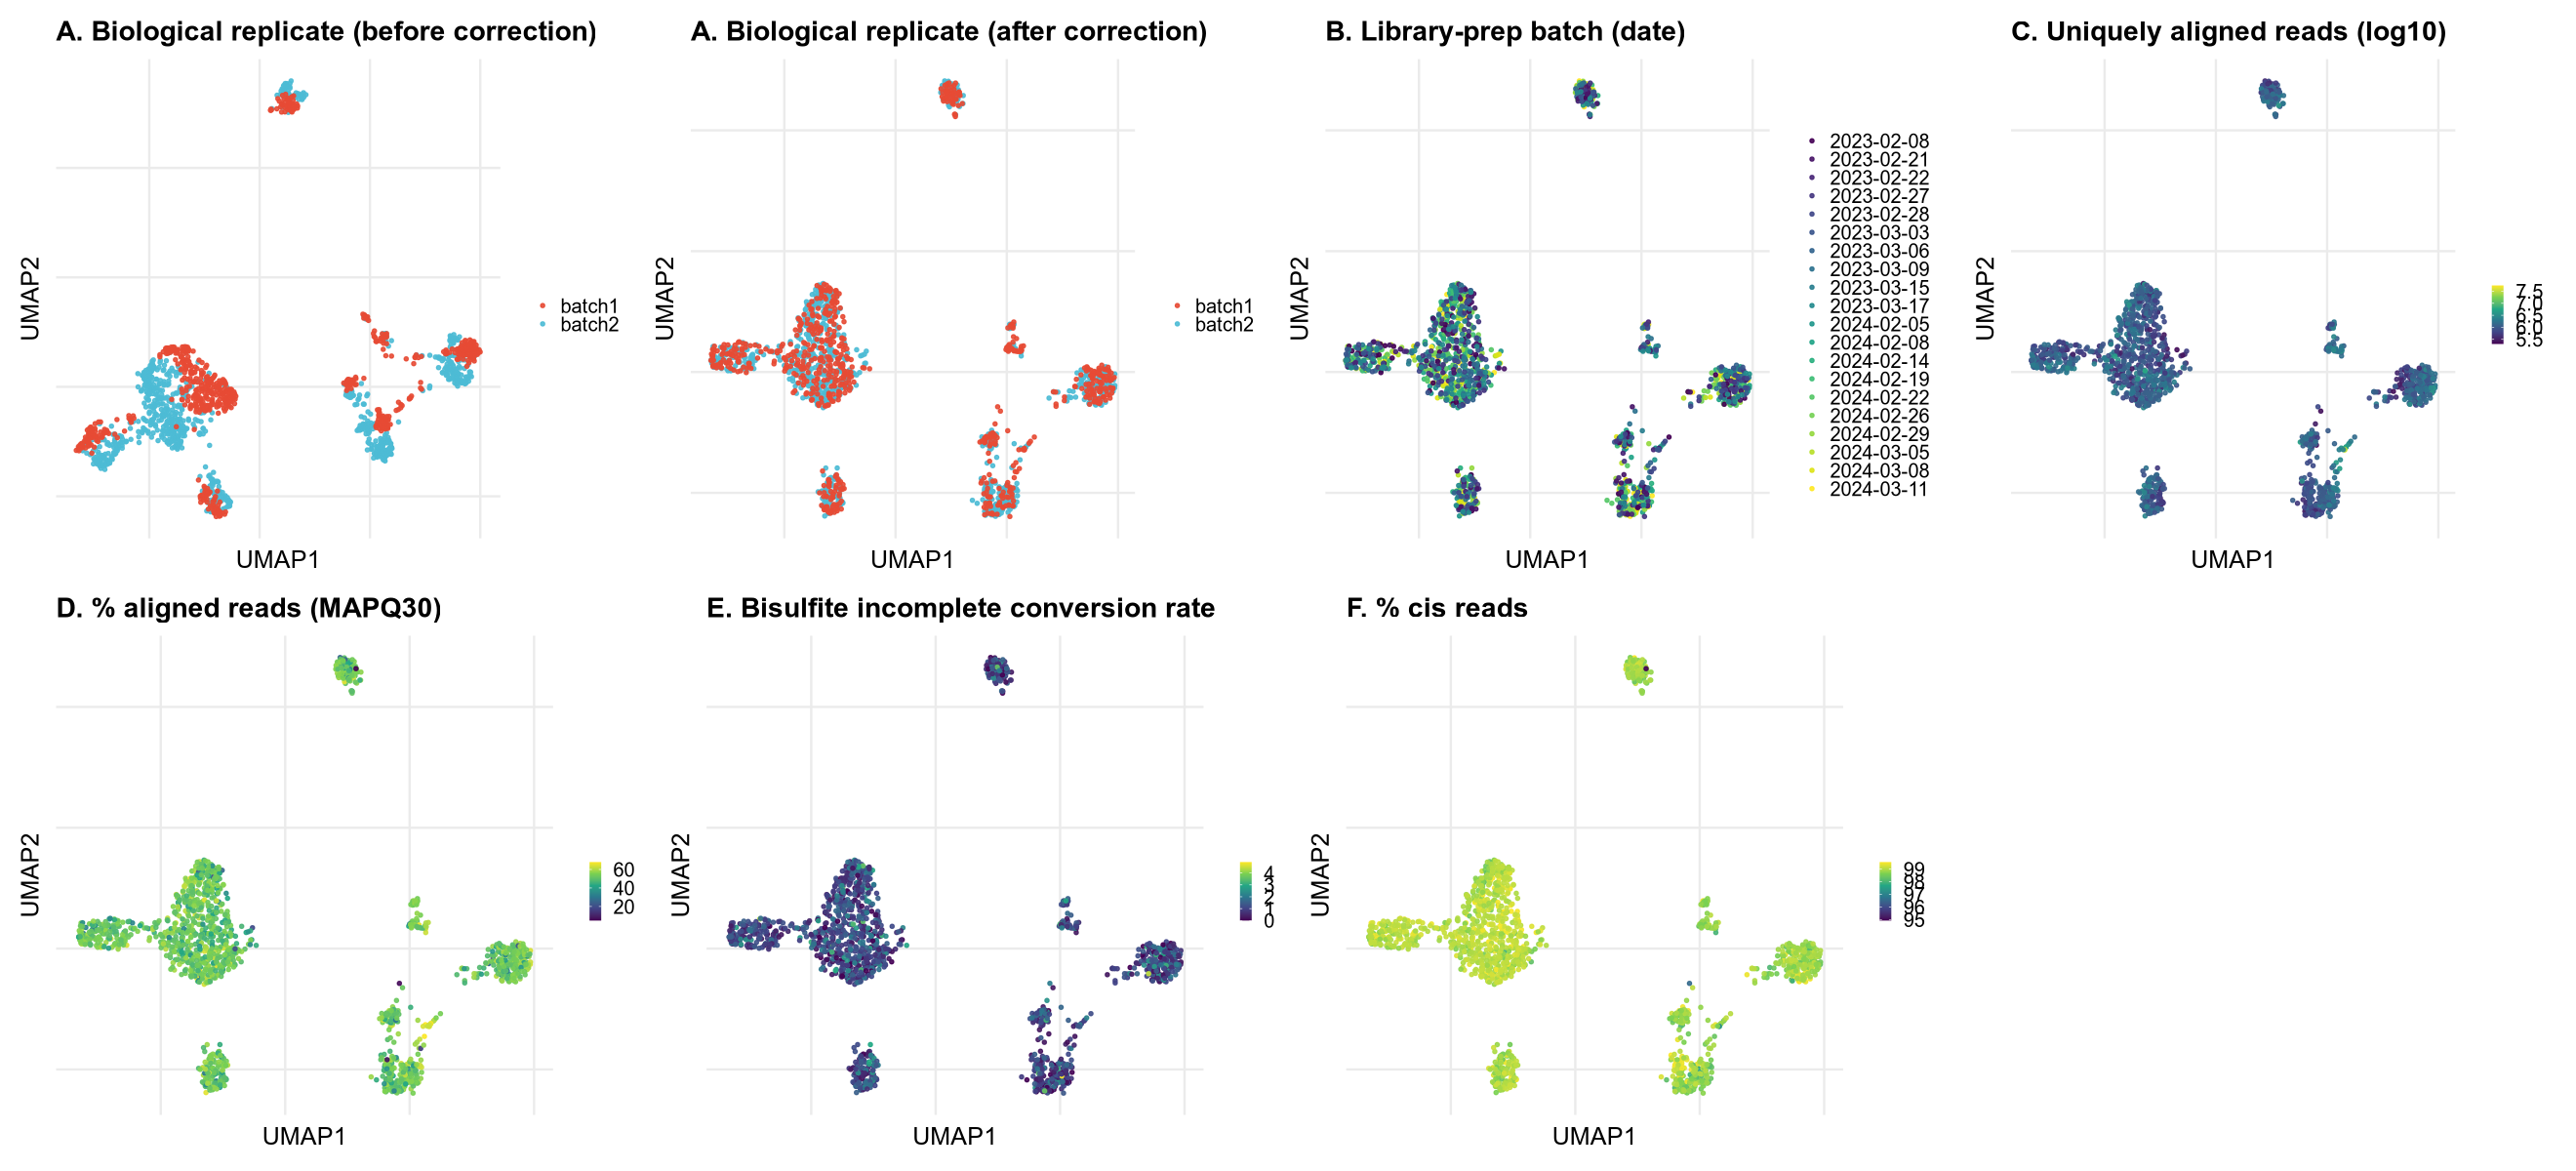

In [29]:
options(repr.plot.width = 22, repr.plot.height = 10)
# §8.7c.2 QC / batch panels on the integrated UMAP.
# Resume-friendly: load saved metadata / layouts if the in-session objects are absent.
if (!exists("submetadata"))
  submetadata <- read.table(file.path(OUT_TAB, "..", "annotation", "metadata_with_cell_type.txt"),
                            header = TRUE, sep = "\t", row.names = 1, check.names = FALSE,
                            quote = "", comment.char = "")
if (!exists("joint_umap"))
  joint_umap <- list(layout = as.matrix(read.table(file.path(OUT_TAB, "joint_umap.txt"),
                     header = TRUE, row.names = 1, check.names = FALSE)))
if (!exists("joint_umap_uncorr"))
  joint_umap_uncorr <- list(layout = as.matrix(read.table(file.path(OUT_TAB, "joint_umap_uncorrected.txt"),
                     header = TRUE, row.names = 1, check.names = FALSE)))

# plate_ID / library_prep_date come from submetadata (merged in §3 from the two
# library sample sheets) — nothing is read ad-hoc here.
stopifnot("library_prep_date" %in% colnames(submetadata))
cat("library_prep_date coverage:",
    sum(!is.na(submetadata[rownames(joint_umap$layout), "library_prep_date"])),
    "/", nrow(joint_umap$layout), "\n")

num <- function(x) as.numeric(as.character(x))
build_qc_df <- function(layout) {
  cells <- rownames(layout)
  d <- data.frame(UMAP1 = layout[, 1], UMAP2 = layout[, 2], row.names = cells)
  s <- submetadata[cells, "sample"]
  d$replicate <- ifelse(s == "scNH", "batch1", ifelse(s == "batch2", "batch2", s))
  d$Library_prep_date <- factor(submetadata[cells, "library_prep_date"])  # B (merged in §3)
  d$log10_uniq   <- log10(num(submetadata[cells, "mapq30num"]))  # C
  d$pct_aligned  <- num(submetadata[cells, "mapq30rate"])        # D
  d$incompl_conv <- num(submetadata[cells, "noncpg_chrM"])       # E (chrM non-CpG = incomplete conversion)
  cisn <- num(submetadata[cells, "cisnum"]); trn <- num(submetadata[cells, "transnum"])
  d$pct_cis <- 100 * cisn / (cisn + trn)                         # F
  d
}
df_after  <- build_qc_df(joint_umap$layout)
df_before <- build_qc_df(joint_umap_uncorr$layout)

qc_theme <- theme_minimal(base_size = 15) +      # publication-size text
  theme(legend.position = "right", axis.text = element_blank(),
        panel.grid.minor = element_blank(),
        plot.title   = element_text(size = 17, face = "bold"),
        axis.title   = element_text(size = 15),
        legend.text  = element_text(size = 12),
        legend.title = element_text(size = 13),
        legend.key.size = unit(0.5, "lines"))
qc_cont <- function(d, col, title)
  ggplot(d, aes(UMAP1, UMAP2, colour = .data[[col]])) +
    geom_point(size = 0.9, alpha = 0.9) +
    scale_color_viridis_c(name = "", na.value = "grey85") + ggtitle(title) + qc_theme
qc_catp <- function(d, col, title, pal = NULL) {
  g <- ggplot(d, aes(UMAP1, UMAP2, colour = .data[[col]])) +
    geom_point(size = 0.9, alpha = 0.9) + ggtitle(title) + qc_theme
  if (!is.null(pal)) g + scale_color_manual(values = pal, na.value = "grey85", name = "")
  else            g + scale_color_viridis_d(na.value = "grey85", name = "")
}
rep_pal <- c(batch1 = "#E64B35", batch2 = "#4DBBD5")

pA0 <- qc_catp(df_before, "replicate", "A. Biological replicate (before correction)", rep_pal)
pA1 <- qc_catp(df_after,  "replicate", "A. Biological replicate (after correction)",  rep_pal)
pB  <- qc_catp(df_after[!is.na(df_after$Library_prep_date), ], "Library_prep_date", "B. Library-prep batch (date)")  # drop NA-date cells
pC  <- qc_cont(df_after,  "log10_uniq",   "C. Uniquely aligned reads (log10)")
pD  <- qc_cont(df_after,  "pct_aligned",  "D. % aligned reads (MAPQ30)")
pE  <- qc_cont(df_after,  "incompl_conv", "E. Bisulfite incomplete conversion rate")
pF  <- qc_cont(df_after,  "pct_cis",      "F. % cis reads")

qc_panel <- (pA0 | pA1 | pB | pC) / (pD | pE | pF | patchwork::plot_spacer())
ggsave_both(file.path(OUT_FIG, "joint_umap_qc_panels"), qc_panel, 22, 10)
qc_panel

## §8.8 Per-modality UMAPs (Chen et al. 2026 Fig. 4b style)

Four side-by-side UMAPs — HCG methylation, GCH accessibility, 3D Genome
(Hi-C), Joint embedding — every cell colored by the cortex `cell_type`
annotation from §8. Single shared legend on the right. Mirrors Fig. 4b
of Chen et al. *Gene regulatory landscape dissected by single-cell
four-omics sequencing*.

wrote figures/umap_fig4b_style.pdf (4 panels incl. joint)


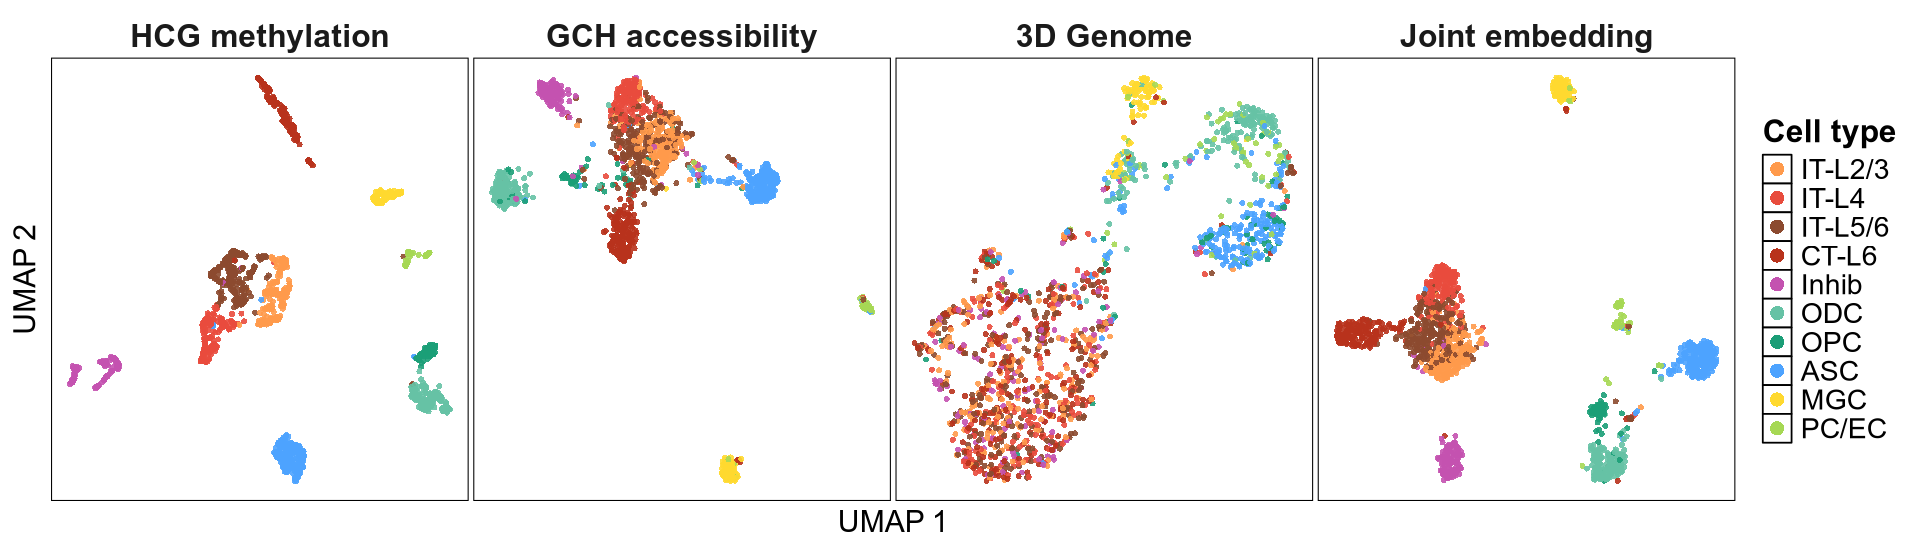

In [30]:
options(repr.plot.width = 16, repr.plot.height = 4.6)
# §8.8 Four-panel per-modality UMAPs (Chen et al. 2026 Fig. 4b style)
# HCG / GCH / HiC / Joint. cell_type carried only in the legend (no overlaid
# text), axis tick values hidden, panels rendered side-by-side.
stopifnot("cell_type" %in% colnames(submetadata),
          exists("HCG.umap"), exists("gch_umap"), exists("hic_umap"),
          exists("joint_umap"))

if (!exists("PUB_BASE")) PUB_BASE <- 16
# Resolve a font that the active PDF device can actually render. ggplot/grid
# uses the PDF "Helvetica" family by default, so we leave element_text $family
# unset (NULL -> inherit) below. This avoids the "invalid font type" error
# that arises when PUB_FONT is set to a family not registered in the device
# (e.g., a leftover "Arial" from a previous notebook run).
PUB_FONT <- NULL  # force-clear any stale value left over from earlier runs

build_modality_df <- function(layout_mat, modality) {
  cells <- intersect(rownames(layout_mat), rownames(submetadata))
  data.frame(cell      = cells,
             UMAP1     = layout_mat[cells, 1],
             UMAP2     = layout_mat[cells, 2],
             cell_type = factor(submetadata[cells, "cell_type"],
                                levels = names(celltype_colors)),
             modality  = modality,
             stringsAsFactors = FALSE)
}
panels <- list(
  HCG   = build_modality_df(HCG.umap$layout,   "HCG methylation"),
  GCH   = build_modality_df(gch_umap$layout,   "GCH accessibility"),
  HiC   = build_modality_df(hic_umap$layout,   "3D Genome"),
  JOINT = build_modality_df(joint_umap$layout, "Joint embedding")
)
panel_levels <- vapply(panels, function(p) p$modality[1], character(1))
df_all <- do.call(rbind, panels)
df_all$modality <- factor(df_all$modality, levels = panel_levels)
df_all <- df_all[!is.na(df_all$cell_type), ]

fig4b_theme <- theme(
  panel.background = element_blank(), panel.grid = element_blank(),
  panel.border     = element_rect(colour = "black", fill = NA, linewidth = 0.6),
  axis.text        = element_blank(),
  axis.ticks       = element_blank(),
  axis.title       = element_text(size = PUB_BASE + 2),
  strip.background = element_blank(),
  strip.text       = element_text(size = PUB_BASE + 3, face = "bold"),
  legend.title     = element_text(size = PUB_BASE + 3, face = "bold"),
  legend.text      = element_text(size = PUB_BASE + 1),
  legend.key       = element_rect(fill = "white"),
  legend.position  = "right",
  panel.spacing.x  = unit(0, "lines"),
  plot.margin      = ggplot2::margin(8, 8, 8, 8)  # namespace-qualified: §8c attaches
                                                  # randomForest, whose margin() generic
                                                  # masks ggplot2::margin and errors with
                                                  # "8 is not a factor"
)

p_fig4b <- ggplot(df_all, aes(UMAP1, UMAP2, colour = cell_type)) +
  geom_point(size = 1.7, alpha = 0.9, stroke = 0) +
  scale_color_manual(values = celltype_colors, name = "Cell type", na.value = "grey80") +
  facet_wrap(~ modality, nrow = 1, scales = "free") +
  labs(x = "UMAP 1", y = "UMAP 2") +
  fig4b_theme +
  guides(colour = guide_legend(override.aes = list(size = 4, alpha = 1)))

ggsave_both(file.path(OUT_FIG, "umap_fig4b_style"), p_fig4b, 16, 4.6)
cat("wrote figures/umap_fig4b_style.pdf (4 panels incl. joint)\n")
p_fig4b


## §9 Save final outputs

In [31]:
# §9 Save final outputs
labeled <- !is.na(submetadata$cell_type)
for (ct in names(celltype_colors)) {
  cells_ct <- rownames(submetadata)[labeled & submetadata$cell_type == ct]
  safe <- gsub("[^A-Za-z0-9]+", "_", ct)
  writeLines(cells_ct, file.path(ANN_DIR, sprintf("%s_cells.txt", safe)))
}

ct_tbl <- data.frame(
  cell = rownames(submetadata)[labeled],
  cell_type = submetadata$cell_type[labeled],
  stringsAsFactors = FALSE
)
write.table(ct_tbl, file.path(ANN_DIR, "cell_type_table.tsv"),
            sep = "\t", quote = FALSE, row.names = FALSE)

# Column layout mirrors subset_clustering/250kb/annotation/metadata_with_cell_type.txt:
# the QC/base block first, then the annotation block, then plate_ID and
# library_prep_date LAST. cell_type_prior (the earlier annotation, kept only for a
# concordance check that is not part of this notebook) is dropped -- it must not
# ship in the released file.
# The old file's cell_type_original / cell_type_nn / cell_type_preCorrect have no
# de novo analogue: there is no k-NN imputation and no manual correction step.
# leiden_cluster (the plain single-seed Leiden cluster) replaces them. There is
# no rescued flag: plain Leiden assigns every cell, so nothing is rescued.
.meta_out <- submetadata
.meta_out$cell_type_prior <- NULL
.tail <- c("plate_ID", "library_prep_date")
.ann  <- c("cell_type", "cluster_color", "cell_type_fct", "leiden_cluster")
.base <- setdiff(colnames(.meta_out), c(.ann, .tail))
.meta_out <- .meta_out[, c(.base, intersect(.ann, colnames(.meta_out)),
                           intersect(.tail, colnames(.meta_out))), drop = FALSE]
write.table(.meta_out,
            file.path(ANN_DIR, "metadata_with_cell_type.txt"),
            sep = "\t", quote = FALSE, row.names = TRUE, col.names = NA)
cat(sprintf("metadata columns (%d): %s\n", ncol(.meta_out),
            paste(colnames(.meta_out), collapse = ", ")))

cat("Saved under", ANN_DIR, "\n")
cat("  - <celltype>_cells.txt           (one file per cell type)\n")
cat("  - cell_type_table.tsv            (cell<TAB>cell_type, labeled only)\n")
cat("  - metadata_with_cell_type.txt    (full submetadata, all QC-passed cells)\n")

metadata columns (32): prefix, dataset, uniquemap, mapq30rate, mapq30num, fragnum, cisnum, cis1kbnum, cis10kbnum, transnum, cis1kbrate, transrate, noncpg_chrM, endo_chrM, exo_chrM, noncpg, endo, exo, GCH, HCG, name, cell, sample, hcg_cluster, hic_cluster, gch_cluster, cell_type, cluster_color, cell_type_fct, leiden_cluster, plate_ID, library_prep_date


Saved under /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/subset_clustering/250kb_denovo/annotation 


  - <celltype>_cells.txt           (one file per cell type)


  - cell_type_table.tsv            (cell<TAB>cell_type, labeled only)


  - metadata_with_cell_type.txt    (full submetadata, all QC-passed cells)


In [32]:
# §9b Per-cell-type pseudobulk matrices (HCG + GCH, three region definitions).
# READ-WEIGHTED, matching every other analysis here:
#     rate[type, gene] = sum(mc over that type's cells) / sum(cov over them)
# NOT mean(mc/cov) across cells -- a per-cell mean would weight a 3-read cell the
# same as a 300-read cell. On this data the two differ by up to 0.067 (e.g. Pvalb
# at the Pvalb locus: 0.307 read-weighted vs 0.374 as a mean of rates).
suppressPackageStartupMessages(library(Matrix))
CNT <- file.path(WORKDIR, "QC", "methylation_matrices")
OUT <- file.path(OUT_DIR, "pseudobulk"); dir.create(OUT, showWarnings = FALSE)
LEV <- cell_type_levels
meta <- submetadata
REGIONS   <- c("gene_tss", "gene_body", "gene")
MODALITIES <- c(HCG = "HCG", GCH = "GCH")

# RUN-ONCE CACHE. This step reads six large per-cell count matrices and takes a
# few minutes. Set RECOMPUTE_PSEUDOBULK <- FALSE to skip it and load the saved
# matrices instead.
#
# The cache is keyed on the ANNOTATION, not just on the files existing: the
# stored pseudobulk carries the cell-type composition it was built from, and if
# that no longer matches submetadata the cache is rejected and recomputed. So
# re-running §8a with different parameters can never leave a stale pseudobulk
# silently in place.
RECOMPUTE_PSEUDOBULK <- TRUE

.stamp_file <- file.path(OUT, "pseudobulk_annotation_stamp.txt")
.stamp_now  <- paste(sprintf("%s:%d", LEV[LEV %in% unique(meta$cell_type)],
                             as.integer(table(meta$cell_type)[
                               LEV[LEV %in% unique(meta$cell_type)]])), collapse = "|")
.cache_ok <- file.exists(.stamp_file) &&
             identical(readLines(.stamp_file, warn = FALSE)[1], .stamp_now) &&
             all(file.exists(file.path(OUT, sprintf("pseudobulk_%s_%s_rate.csv.gz",
                 rep(names(MODALITIES), each = length(REGIONS)), REGIONS))))

if (!RECOMPUTE_PSEUDOBULK && .cache_ok) {
  cat("using cached pseudobulk (annotation stamp matches)\n")
  cat("  ", .stamp_now, "\n")
  pseudobulk <- lapply(setNames(nm = as.vector(outer(names(MODALITIES), REGIONS,
                                                     paste, sep = "_"))),
    function(tag) as.matrix(read.csv(gzfile(file.path(OUT,
      sprintf("pseudobulk_%s_rate.csv.gz", tag))), row.names = 1, check.names = FALSE)))
  cat(sprintf("  loaded %d matrices, %d cell types\n",
              length(pseudobulk), nrow(pseudobulk[[1]])))
} else {
  if (!RECOMPUTE_PSEUDOBULK && !.cache_ok)
    cat("cache MISSING or built from a different annotation - recomputing\n")

summary_rows <- list()
for (mod in names(MODALITIES)) {
  for (reg in REGIONS) {
    f <- file.path(CNT, sprintf("%s_%s_counts.rds", MODALITIES[[mod]], reg))
    if (!file.exists(f)) { cat("  missing:", basename(f), "- skipped\n"); next }
    obj <- readRDS(f)
    cells <- intersect(rownames(meta), colnames(obj$mc))
    grp   <- setNames(meta[cells, "cell_type"], cells)
    types <- LEV[LEV %in% unique(grp)]

    # READ-WEIGHTED: sum(mc) / sum(cov) over the cells of each type
    MC <- sapply(types, function(t) Matrix::rowSums(obj$mc [, names(grp)[grp == t], drop = FALSE]))
    CV <- sapply(types, function(t) Matrix::rowSums(obj$cov[, names(grp)[grp == t], drop = FALSE]))
    RATE <- ifelse(CV > 0, MC / CV, NA_real_)
    dimnames(RATE) <- dimnames(MC) <- dimnames(CV) <- list(rownames(obj$mc), types)

    tag <- sprintf("%s_%s", mod, reg)
    write.csv(round(t(RATE), 6), gzfile(file.path(OUT, sprintf("pseudobulk_%s_rate.csv.gz", tag))))
    write.csv(t(MC), gzfile(file.path(OUT, sprintf("pseudobulk_%s_mc.csv.gz", tag))))
    write.csv(t(CV), gzfile(file.path(OUT, sprintf("pseudobulk_%s_cov.csv.gz", tag))))

    gcov <- colSums(CV); gmc <- colSums(MC)
    summary_rows[[tag]] <- data.frame(
      modality = mod, region = reg, cell_type = types,
      n_cells = as.integer(table(grp)[types]),
      total_cov = as.numeric(gcov[types]),
      global_rate = round(as.numeric(gmc[types] / gcov[types]), 4),
      genes_with_cov = as.integer(colSums(CV > 0)[types]),
      genes_cov_ge100 = as.integer(colSums(CV >= 100)[types]))
    cat(sprintf("%-14s %d genes x %d types written\n", tag, nrow(RATE), ncol(RATE)))
    rm(obj, MC, CV, RATE); invisible(gc(verbose = FALSE))
  }
}
S <- do.call(rbind, summary_rows)
write.csv(S, file.path(OUT, "pseudobulk_summary.csv"), row.names = FALSE)

cat("\n--- per-type coverage, HCG gene_body (the panel used for heatmaps) ---\n")
hb <- S[S$modality == "HCG" & S$region == "gene_body", ]
print(hb[order(-hb$n_cells), c("cell_type","n_cells","total_cov","global_rate",
                               "genes_cov_ge100")], row.names = FALSE)
cat("\n--- global HCG rate by type (neurons should exceed glia) ---\n")
cat(paste(sprintf("  %-8s %.3f", hb$cell_type, hb$global_rate), collapse = "\n"), "\n")

cat("\nwrote per-cell-type pseudobulk to", OUT, "\n")

writeLines(.stamp_now, .stamp_file)   # records the annotation this cache belongs to
}


HCG_gene_tss   21800 genes x 10 types written
HCG_gene_body  21800 genes x 10 types written
HCG_gene       21800 genes x 10 types written
GCH_gene_tss   21800 genes x 10 types written
GCH_gene_body  21800 genes x 10 types written
GCH_gene       21800 genes x 10 types written

--- per-type coverage, HCG gene_body (the panel used for heatmaps) ---
 cell_type n_cells total_cov global_rate genes_cov_ge100
   IT-L5/6     249 155611534      0.7269           20440
       ASC     225 105058074      0.7088           20175
   IT-L2/3     199  89304688      0.7082           20010
     CT-L6     193  82693963      0.7319           19924
     IT-L4     176  79791337      0.7021           19875
       ODC     174  76331284      0.7132           19850
     Inhib     135  61711126      0.7420           19593
       MGC      99  44995151      0.6954           19075
       OPC      69  32133621      0.6894           18494
     PC/EC      58  31543777      0.6714           18431

--- global HCG rate by t